<a href="https://www.kaggle.com/code/lalit7881/ai-startup-funding-hiring-signals-eda-100?scriptVersionId=363462916" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/biswaranjanlipun/ai-startup-funding-and-hiring-signals/README.md
/kaggle/input/datasets/biswaranjanlipun/ai-startup-funding-and-hiring-signals/ai_startup_funding_and_hiring_signals.csv
/kaggle/input/datasets/biswaranjanlipun/ai-startup-funding-and-hiring-signals/sync.py


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/biswaranjanlipun/ai-startup-funding-and-hiring-signals/ai_startup_funding_and_hiring_signals.csv")

In [3]:
df.head()

,Record ID,Date Found,Company,Funding Amount,Funding Round,Event Date,Score,Why It Matters,Hiring Signal,Source Name,Source URL,Status
0,FUND-aa1ca62f7bd79fb6,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,Firmus,$2.85 billion,Late stage,"Fri, 07 Aug 2026 02:48:24 GMT",Sat Apr 07 1900 00:00:00 GMT+0521 (India Stand...,Firmus secured $2.85 billion in funding to exp...,Massive capital allocation towards AI infrastr...,SmartCompany,https://www.smartcompany.com.au,OLD
1,FUND-f88217ba58bfee86,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,Hadrian,$1.4 billion,Growth Round,"Fri, 07 Aug 2026 13:18:44 GMT",96,Hadrian landed $1.4B at a $7.9B valuation to m...,Multi-billion valuation and funding will accel...,Tech Funding News,https://techfundingnews.com,OLD
2,FUND-769a24db473adde4,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,DeepSeek,$8 billion,Growth Round,"Thu, 06 Aug 2026 20:58:14 GMT",95,DeepSeek resumed its $8 billion funding round ...,Substantial capital commitment fuels significa...,PYMNTS.com,https://www.pymnts.com,OLD
3,FUND-efd9495869871b46,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,Zankore,$800 million,Venture Round,"Fri, 07 Aug 2026 03:30:35 GMT",93,Ooredoo led an $800M round into AI startup Zan...,A massive $800M round opens major technical ro...,communicationstoday.co.in,https://www.communicationstoday.co.in,OLD
4,FUND-796f77ff37fee17a,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,Lumilens,$700 million,Venture Round,"Fri, 07 Aug 2026 03:29:16 GMT",92,Lumilens closed $700M with top-tier VCs Peak X...,Large capital raise will directly fund technic...,DealStreetAsia,https://www.dealstreetasia.com,OLD


In [4]:
df.tail()

,Record ID,Date Found,Company,Funding Amount,Funding Round,Event Date,Score,Why It Matters,Hiring Signal,Source Name,Source URL,Status
483,FUND-3154dca4032f838d,Thu Oct 29 2026 08:56:22 GMT+0530 (India Stand...,Casap,$56 Million,Series B,"Wed, 28 Oct 2026 13:00:00 GMT",82,Casap completed a $56M Series B round to power...,Series B expansion indicates strong product-ma...,Fortune,https://fortune.com,NEW
484,FUND-12710622eefc187c,Thu Oct 29 2026 08:56:22 GMT+0530 (India Stand...,Simplismart,$14 Million,Series B,"Wed, 28 Oct 2026 07:44:49 GMT",79,Nvidia directly backed Simplismart in a $14M S...,Strategic backing from Nvidia combined with ra...,AI Insider,https://theaiinsider.tech,NEW
485,FUND-60144736ba01f812,Thu Oct 29 2026 08:56:22 GMT+0530 (India Stand...,Superconductive,$40 Million,Growth Round,"Wed, 28 Oct 2026 10:15:48 GMT",78,The maintainers of Great Expectations secured ...,Funding will fuel product expansion requiring ...,TechTarget,https://techtarget.com,NEW
486,FUND-fc1f19ea5af177bb,Thu Oct 29 2026 08:56:22 GMT+0530 (India Stand...,Plato,$16 Million,Series A,"Wed, 28 Oct 2026 16:02:35 GMT",73,Plato raised $16M in Series A funding to build...,Series A capital will directly fund early core...,Unite.AI,https://www.unite.ai,NEW
487,FUND-81174c1bd85ea110,Thu Oct 29 2026 08:56:22 GMT+0530 (India Stand...,AvalonX,$10 Million,Seed / Early Stage,"Wed, 28 Oct 2026 10:05:28 GMT",70,AvalonX emerged from stealth with $10 million ...,Emerging from stealth with $10M means the comp...,greatreporter,https://greatreporter.com,NEW


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 488 entries, 0 to 487
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Record ID       488 non-null    object
 1   Date Found      488 non-null    object
 2   Company         488 non-null    object
 3   Funding Amount  488 non-null    object
 4   Funding Round   488 non-null    object
 5   Event Date      488 non-null    object
 6   Score           488 non-null    object
 7   Why It Matters  488 non-null    object
 8   Hiring Signal   488 non-null    object
 9   Source Name     488 non-null    object
 10  Source URL      487 non-null    object
 11  Status          488 non-null    object
dtypes: object(12)
memory usage: 45.9+ KB


In [6]:
df.describe()

,Record ID,Date Found,Company,Funding Amount,Funding Round,Event Date,Score,Why It Matters,Hiring Signal,Source Name,Source URL,Status
count,488,488,488,488,488,488,488,488,488,488,487,488
unique,488,66,339,314,80,462,37,488,488,197,217,2
top,FUND-81174c1bd85ea110,Fri Aug 07 2026 23:53:47 GMT+0530 (India Stand...,Blacksmith,Undisclosed,Venture Round,Wed Sep 09 2026 00:00:00 GMT+0530 (India Stand...,88,AvalonX emerged from stealth with $10 million ...,Emerging from stealth with $10M means the comp...,AI Insider,https://theaiinsider.tech,OLD
freq,1,10,7,18,143,8,39,1,1,27,24,478


In [7]:
df.isnull().sum()

Record ID         0
Date Found        0
Company           0
Funding Amount    0
Funding Round     0
Event Date        0
Score             0
Why It Matters    0
Hiring Signal     0
Source Name       0
Source URL        1
Status            0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

Record ID         object
Date Found        object
Company           object
Funding Amount    object
Funding Round     object
Event Date        object
Score             object
Why It Matters    object
Hiring Signal     object
Source Name       object
Source URL        object
Status            object
dtype: object

In [10]:
df.shape

(488, 12)

In [11]:
df.columns

Index(['Record ID', 'Date Found', 'Company', 'Funding Amount', 'Funding Round',
       'Event Date', 'Score', 'Why It Matters', 'Hiring Signal', 'Source Name',
       'Source URL', 'Status'],
      dtype='object')

In [12]:
df.nunique()

Record ID         488
Date Found         66
Company           339
Funding Amount    314
Funding Round      80
Event Date        462
Score              37
Why It Matters    488
Hiring Signal     488
Source Name       197
Source URL        217
Status              2
dtype: int64

## EDA

DATASET OVERVIEW
Rows: 488
Columns: 13

Missing values:
 Record ID                   0
Date Found                488
Company                     0
Funding Amount              0
Funding Round               0
Event Date                 29
Score                       1
Why It Matters              0
Hiring Signal               0
Source Name                 0
Source URL                  1
Status                      0
Funding Amount Numeric    434
dtype: int64

Data types:
 Record ID                         object
Date Found                datetime64[ns]
Company                           object
Funding Amount                    object
Funding Round                     object
Event Date                datetime64[ns]
Score                            float64
Why It Matters                    object
Hiring Signal                     object
Source Name                       object
Source URL                        object
Status                            object
Funding Amount Numeric           f

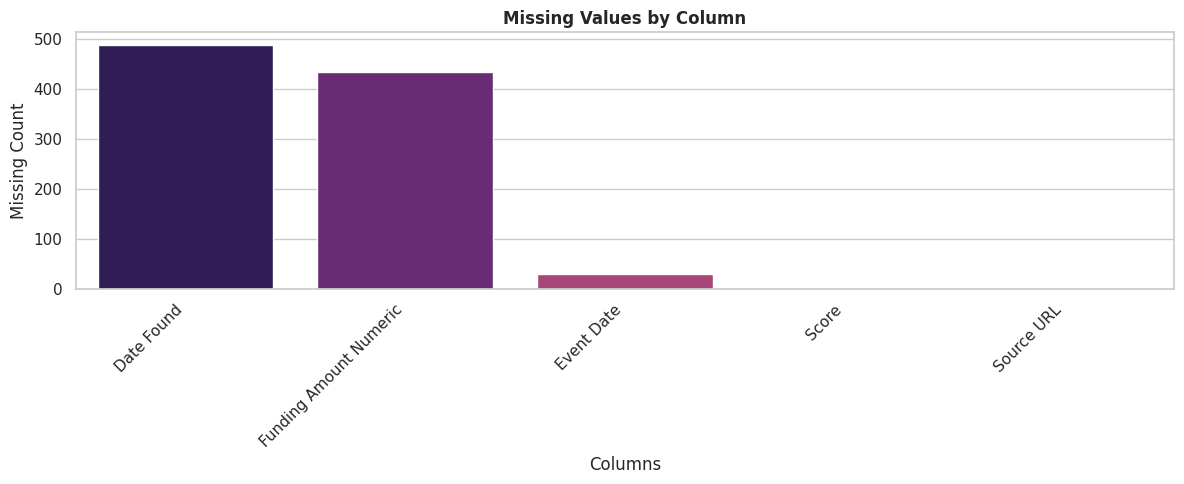

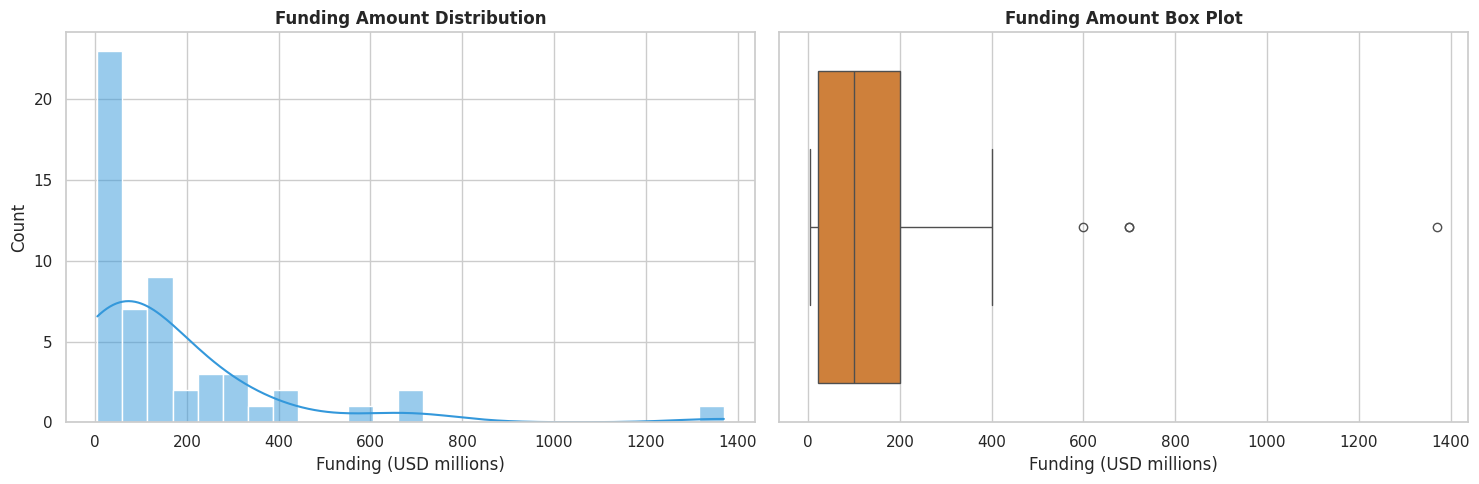

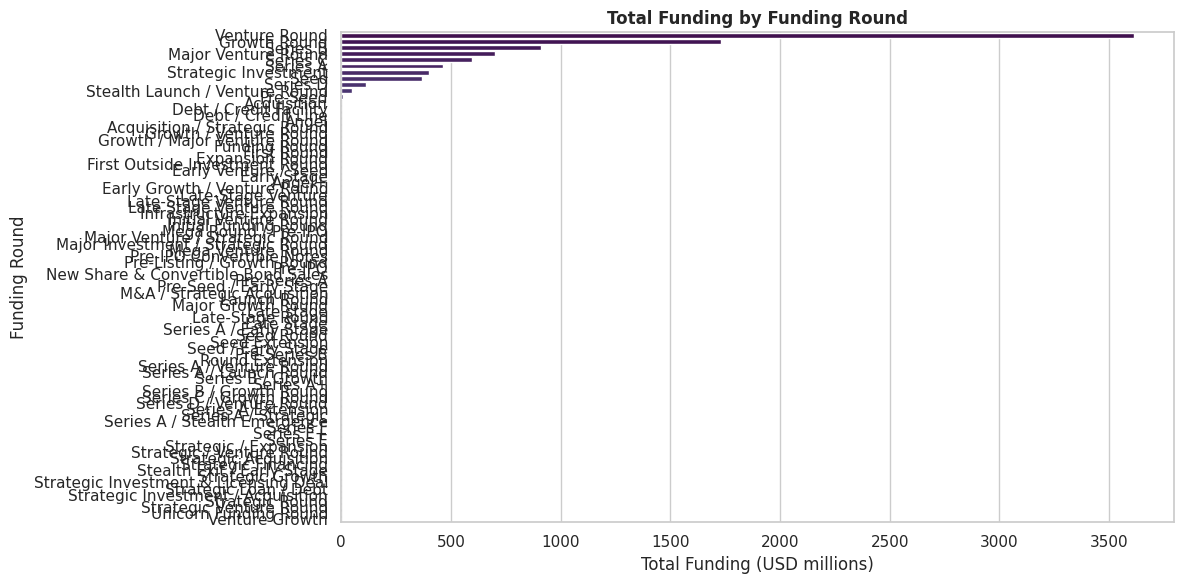

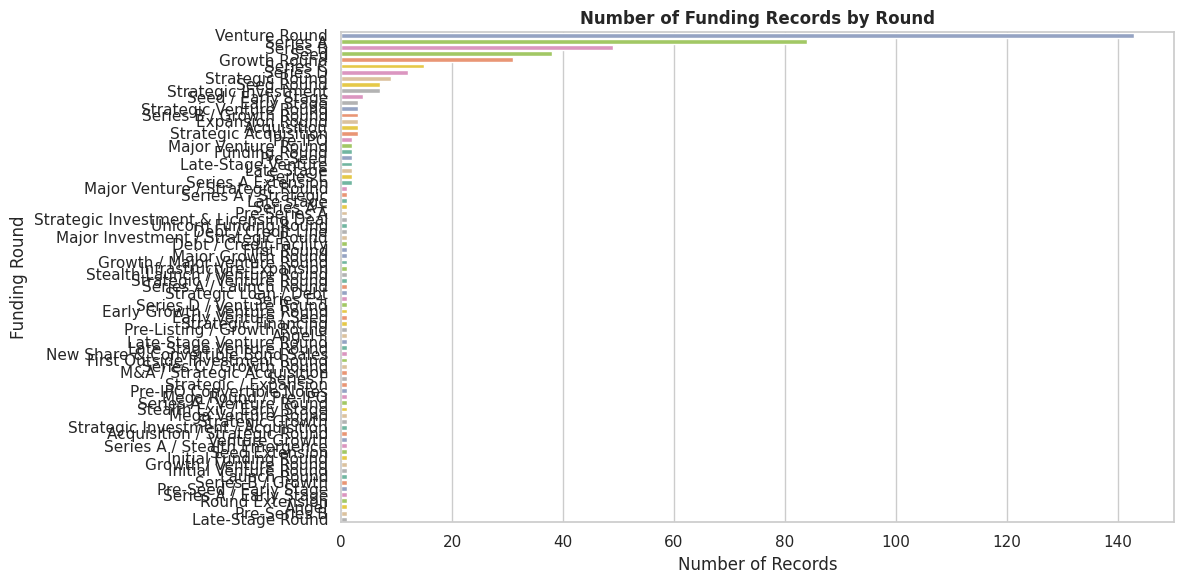

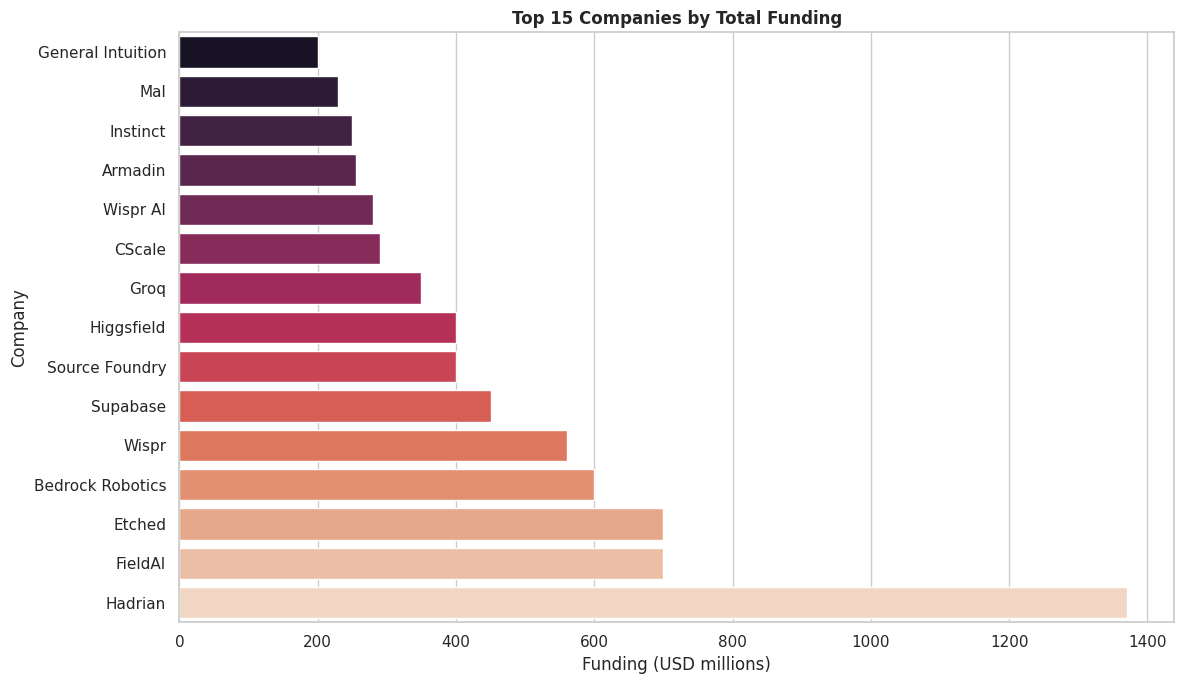

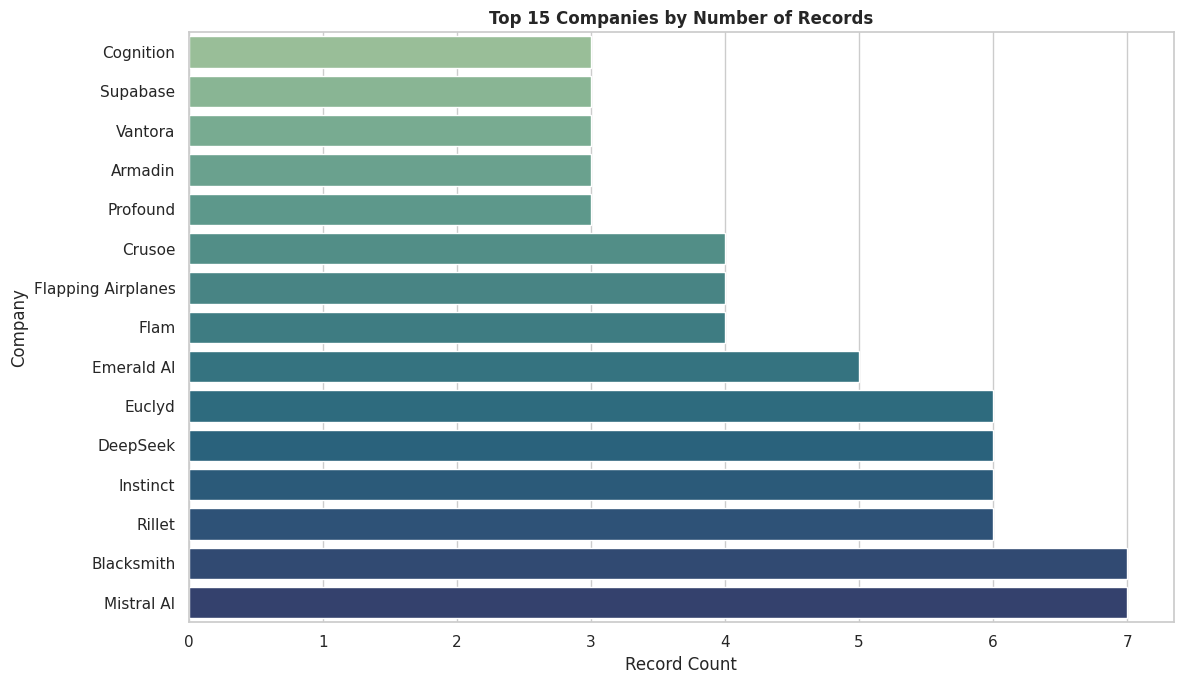

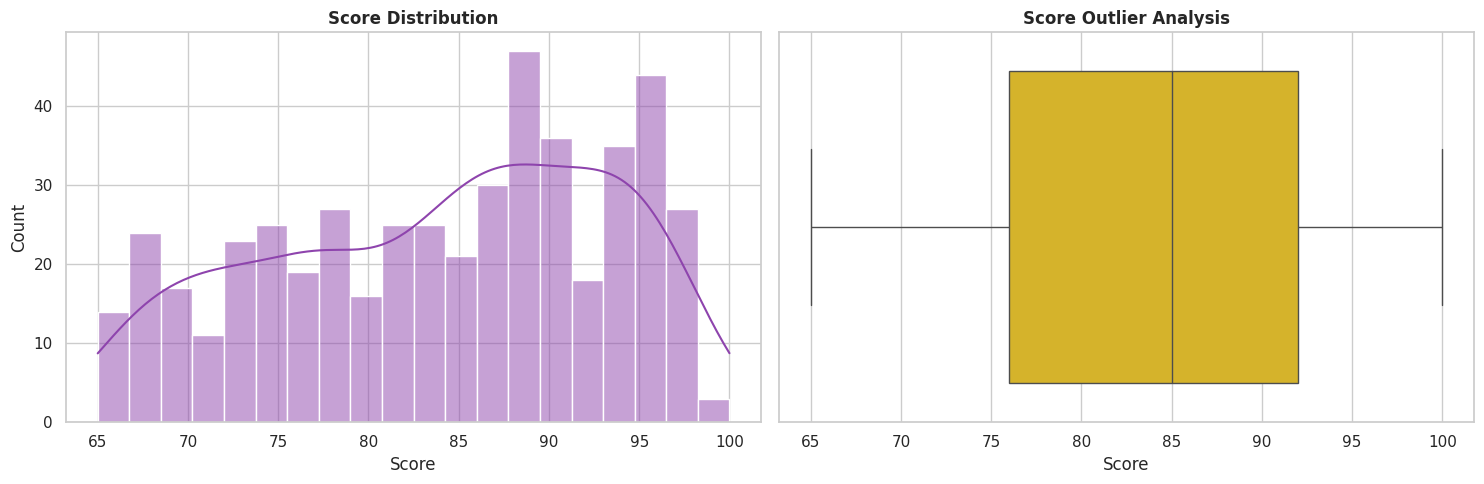

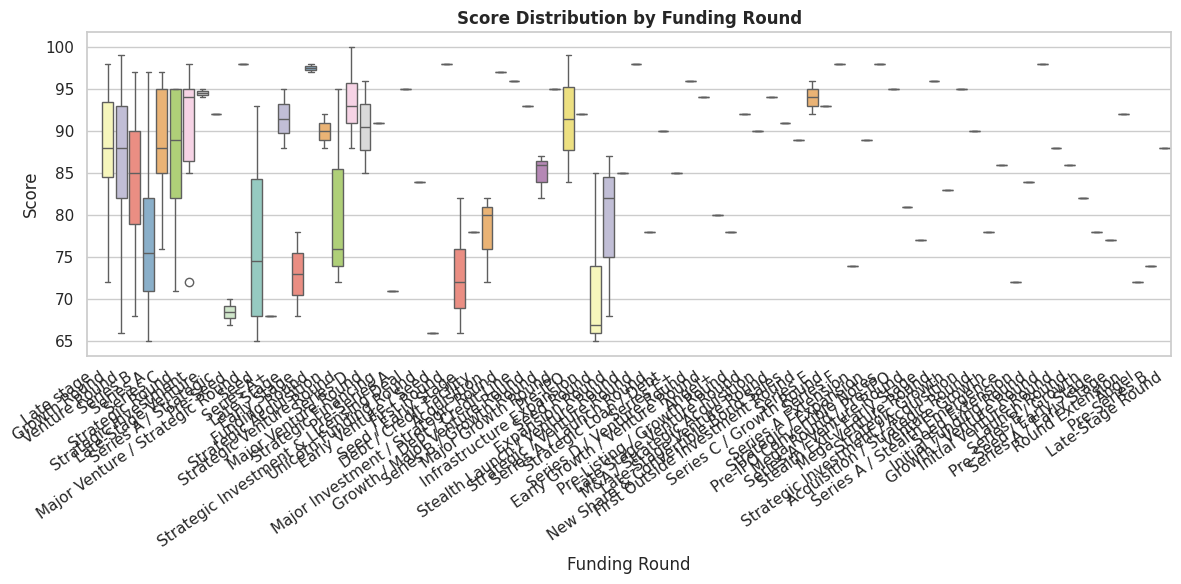

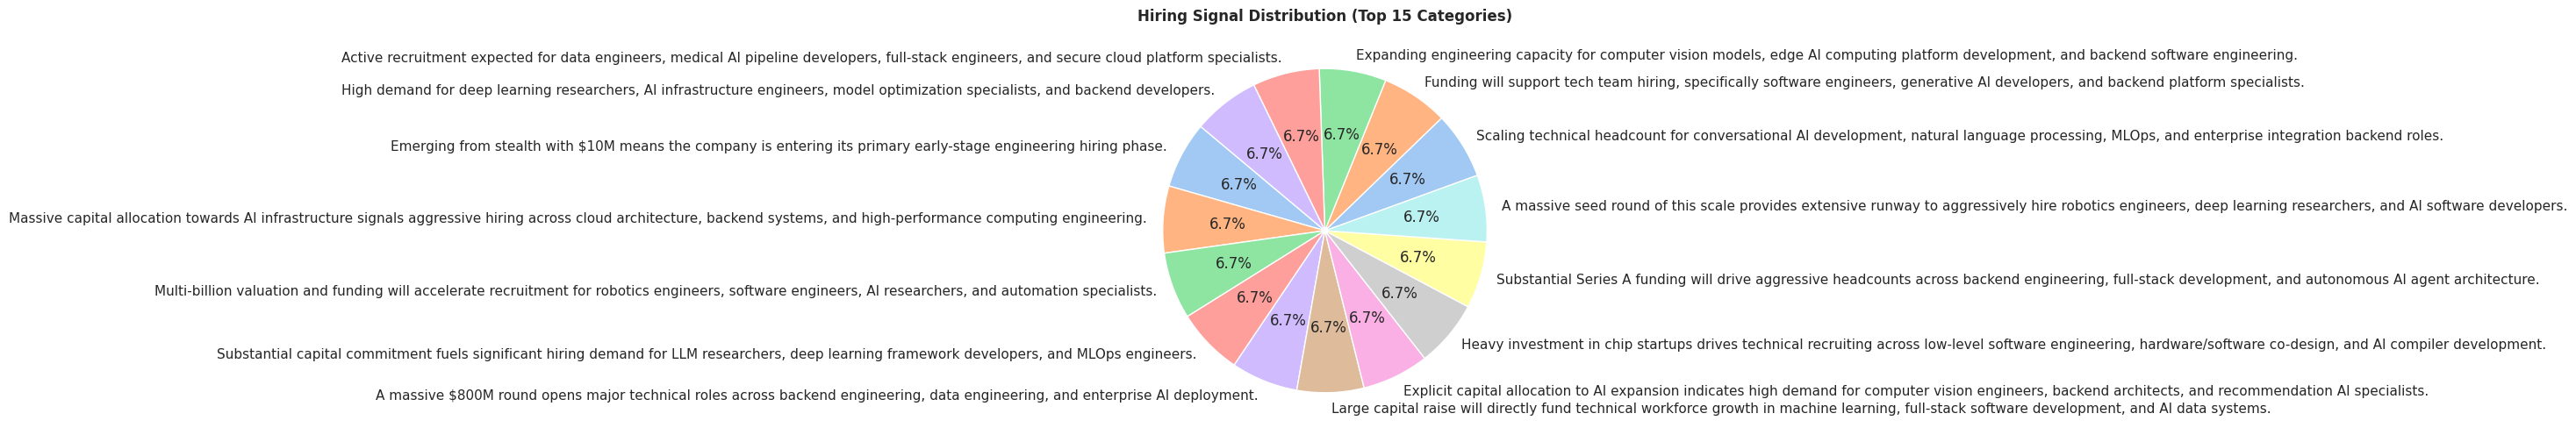

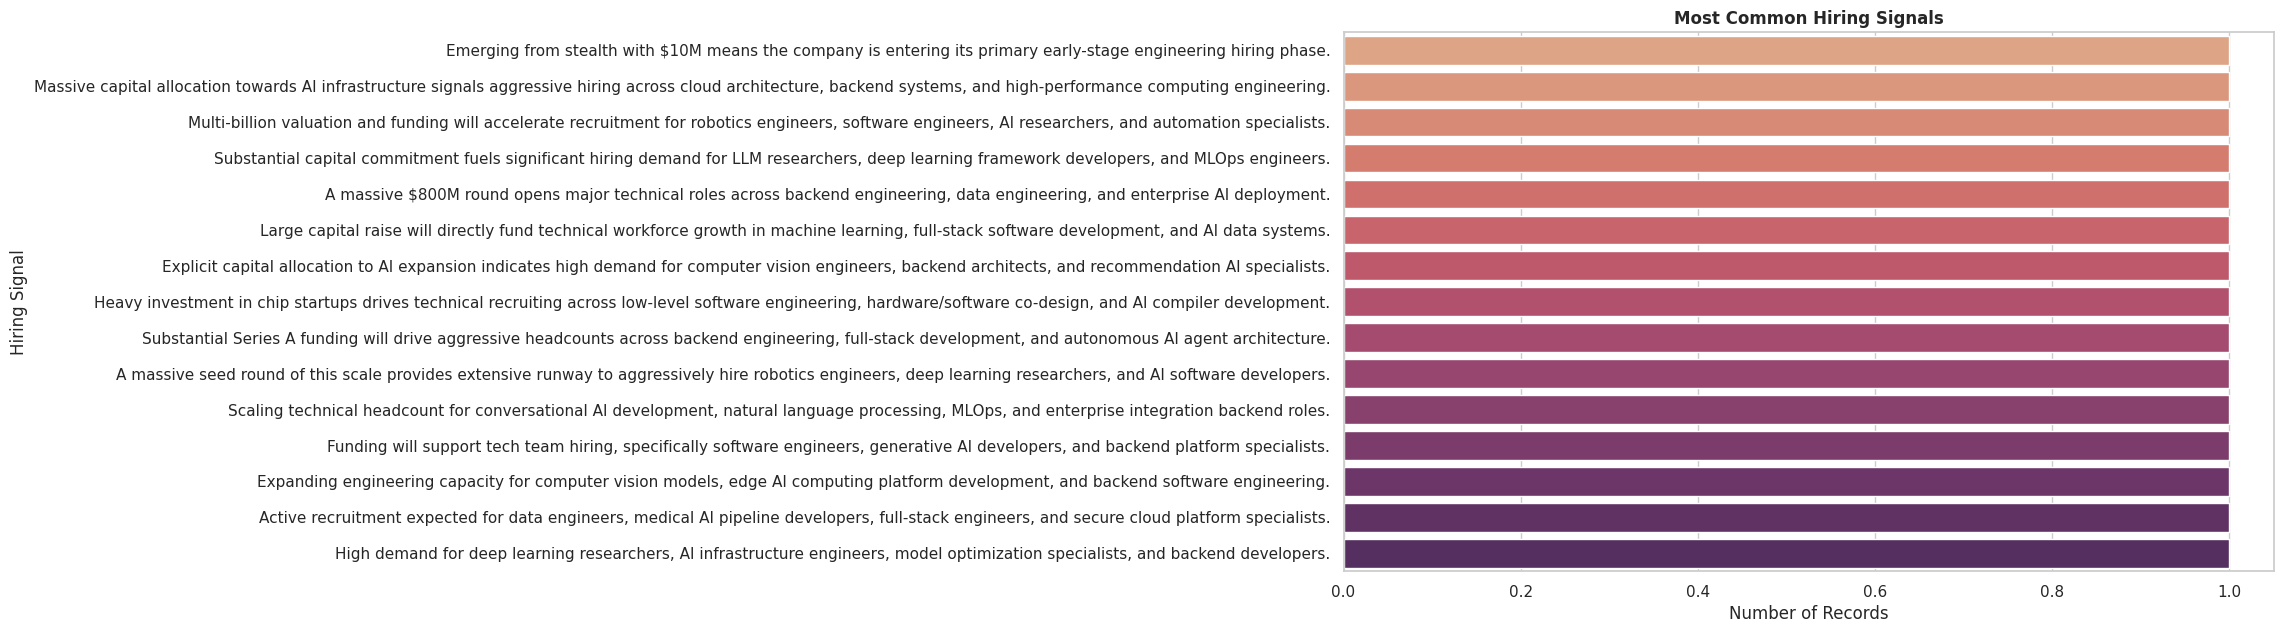

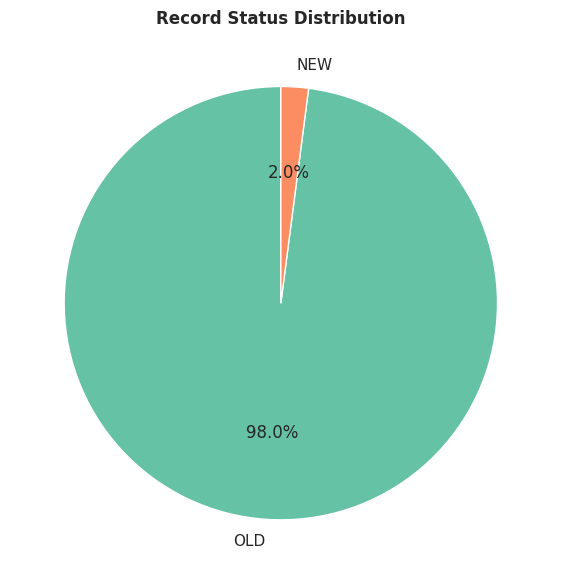

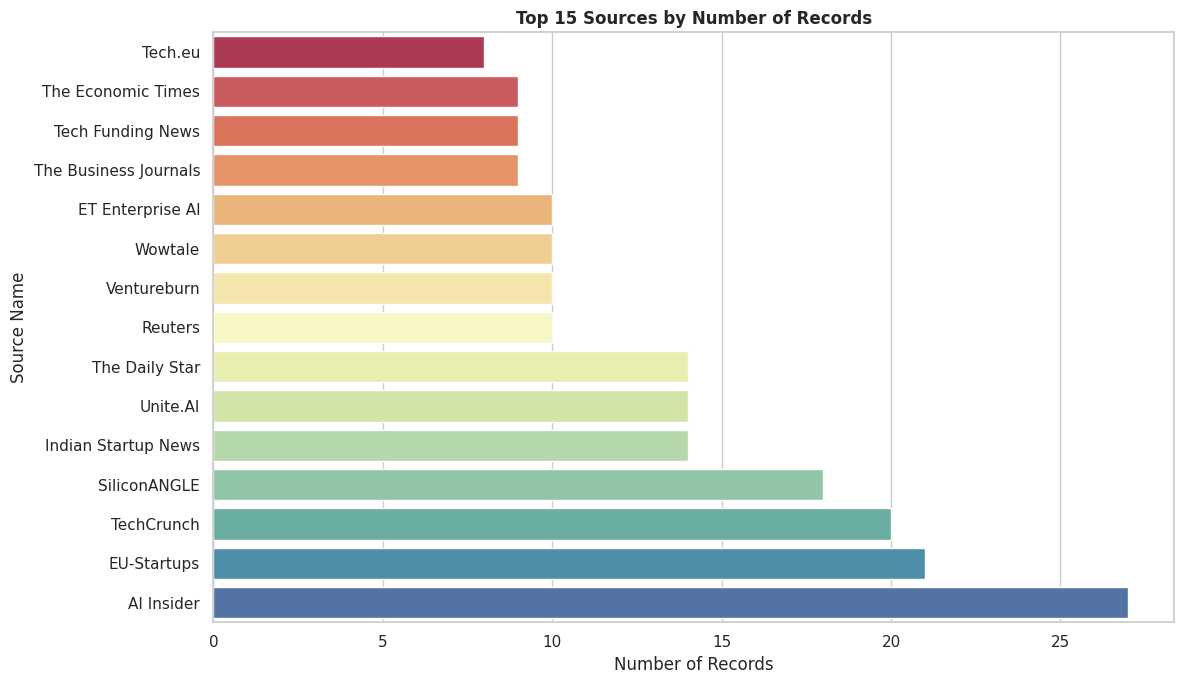

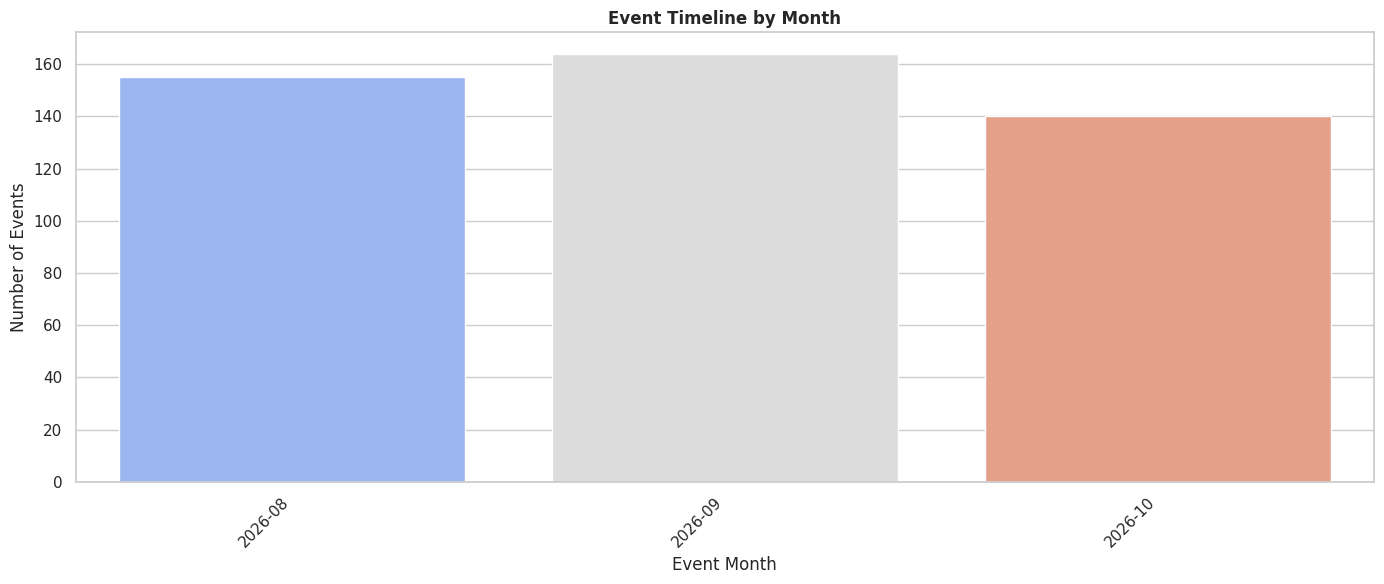

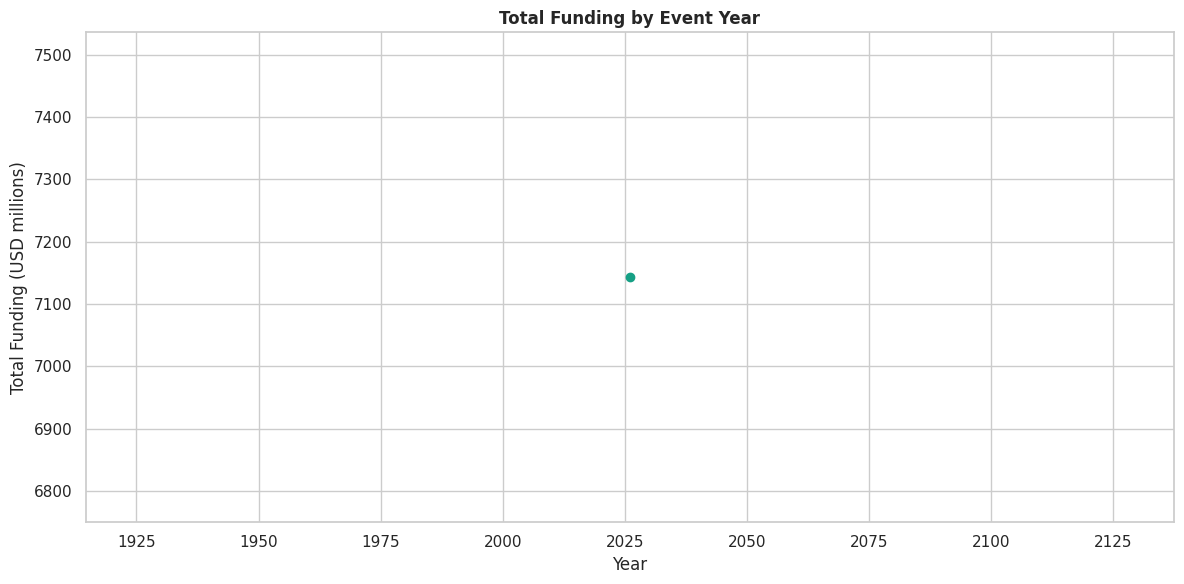

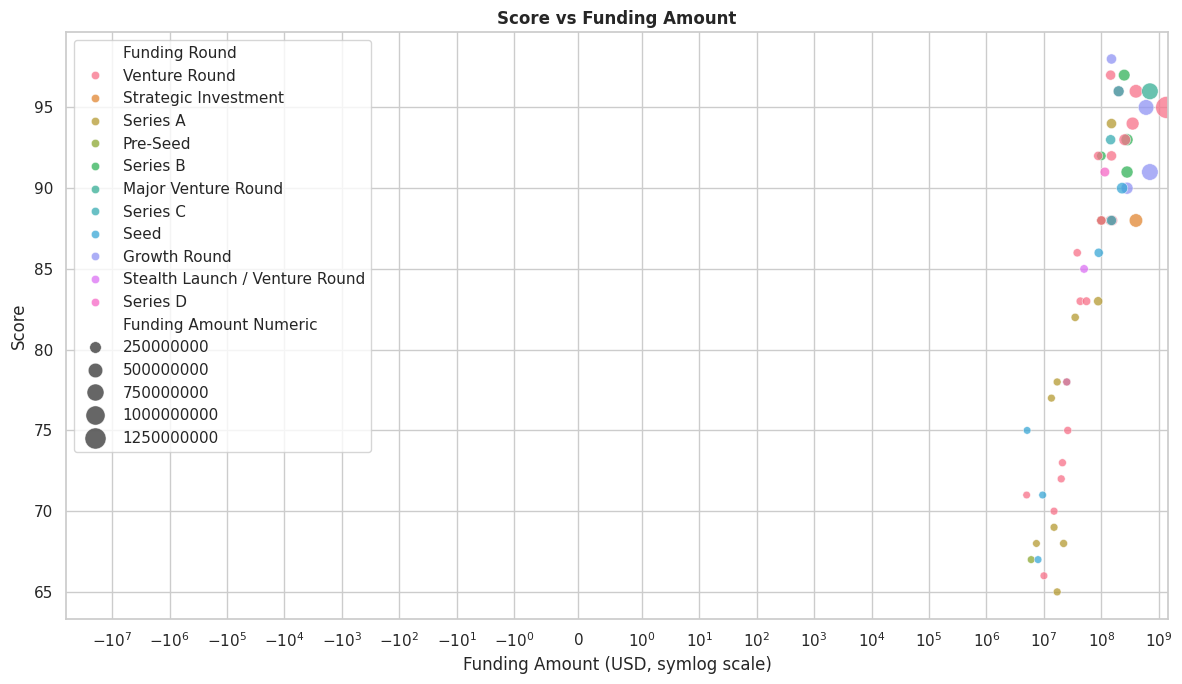

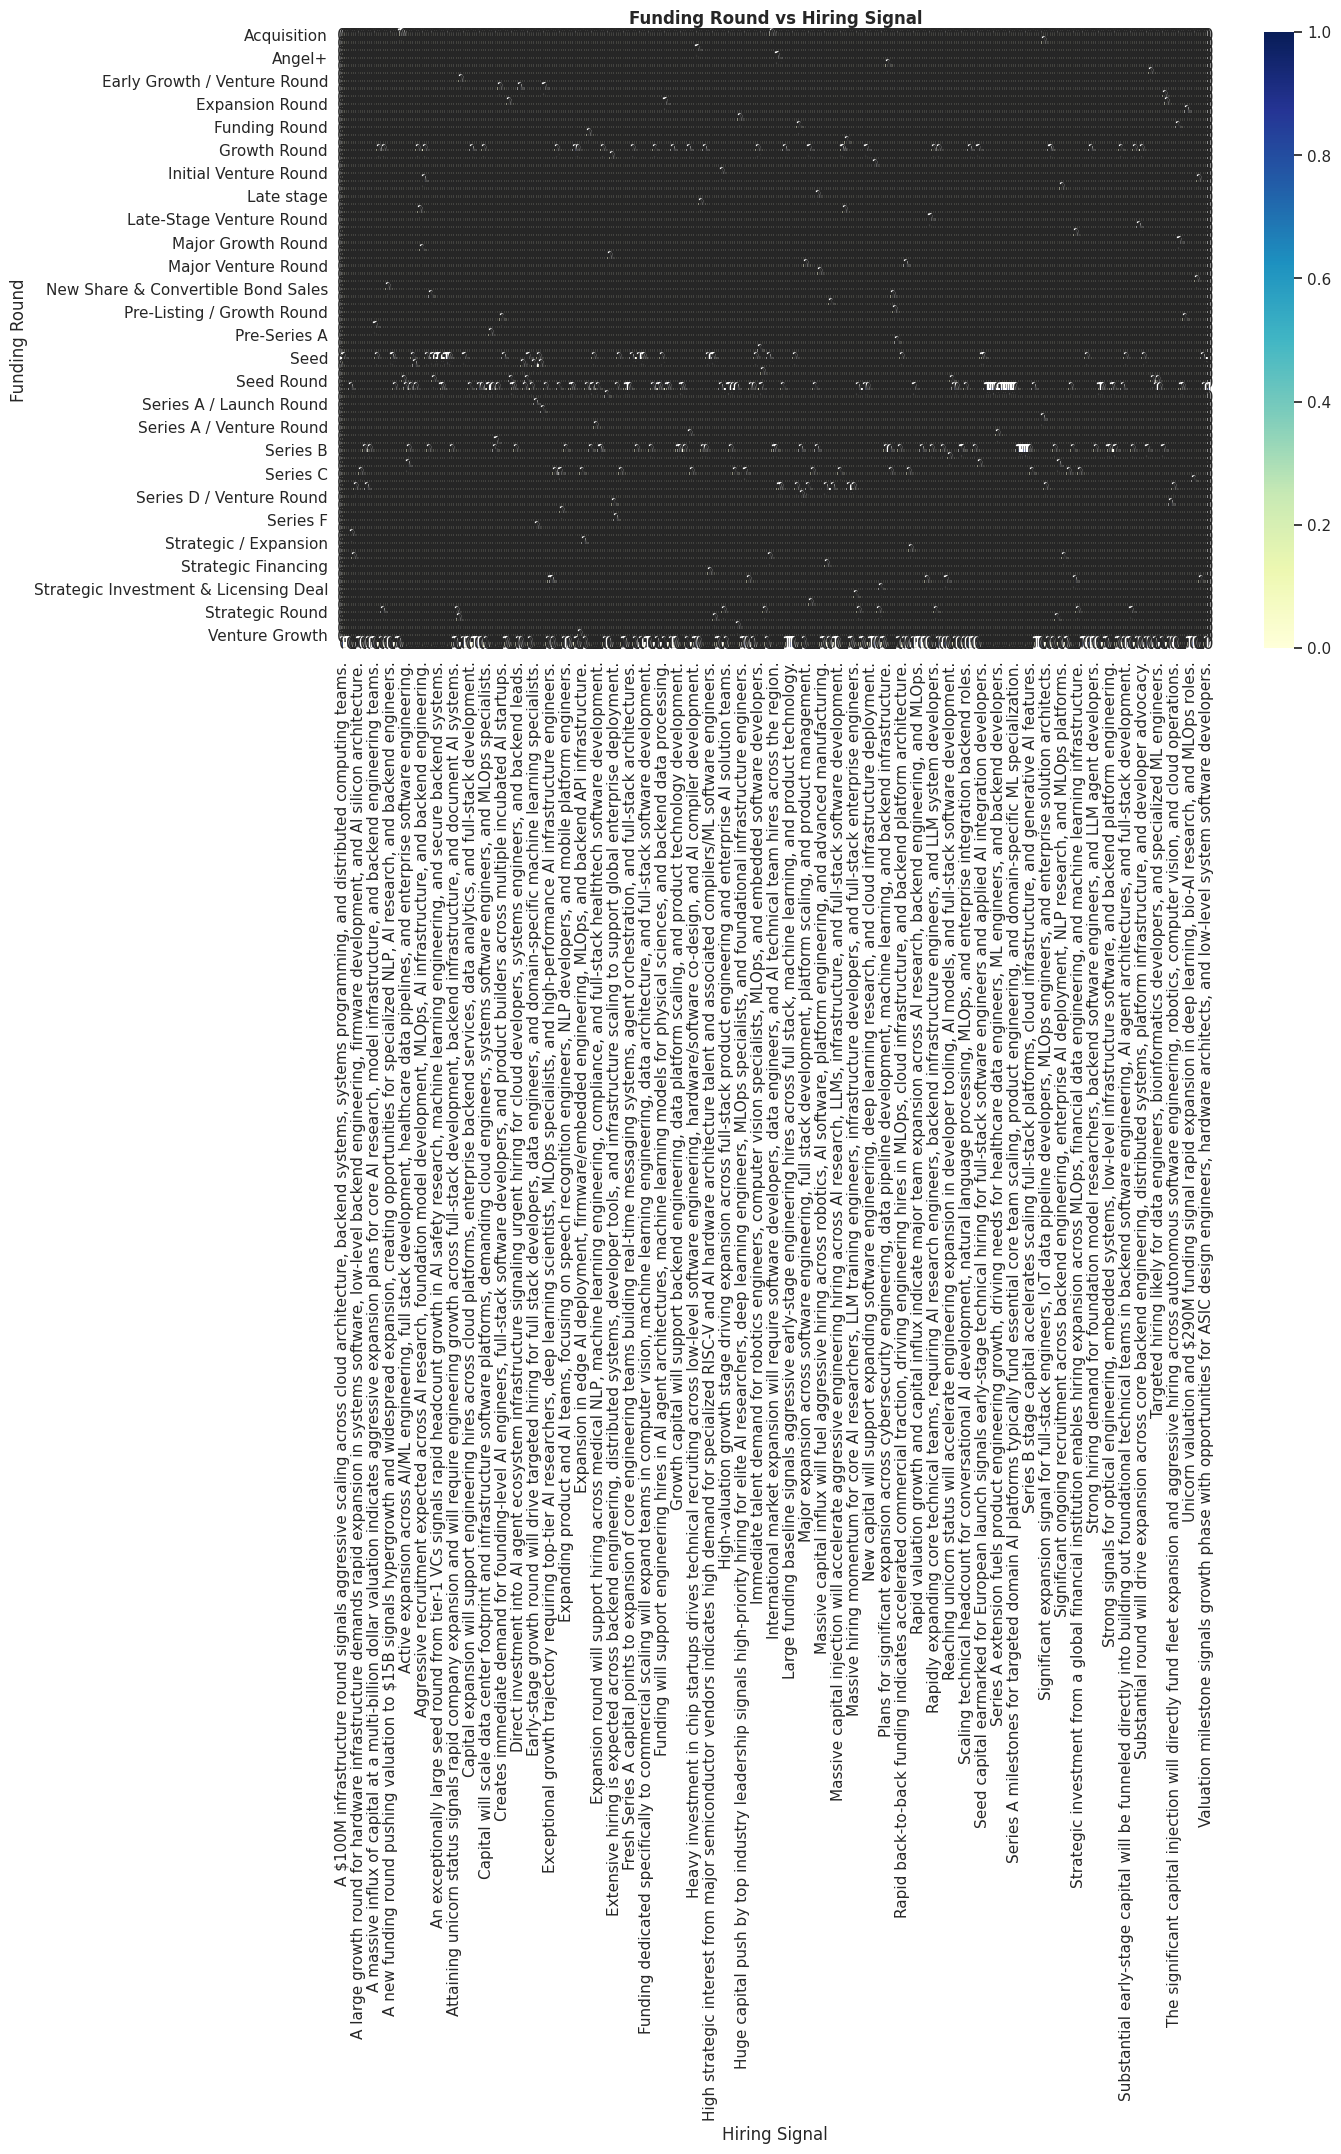

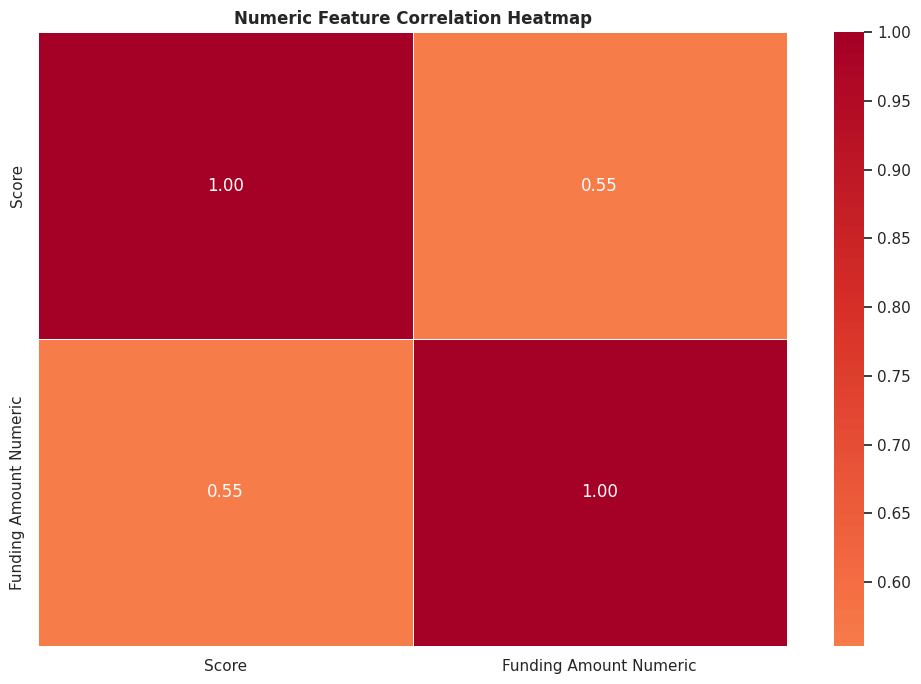

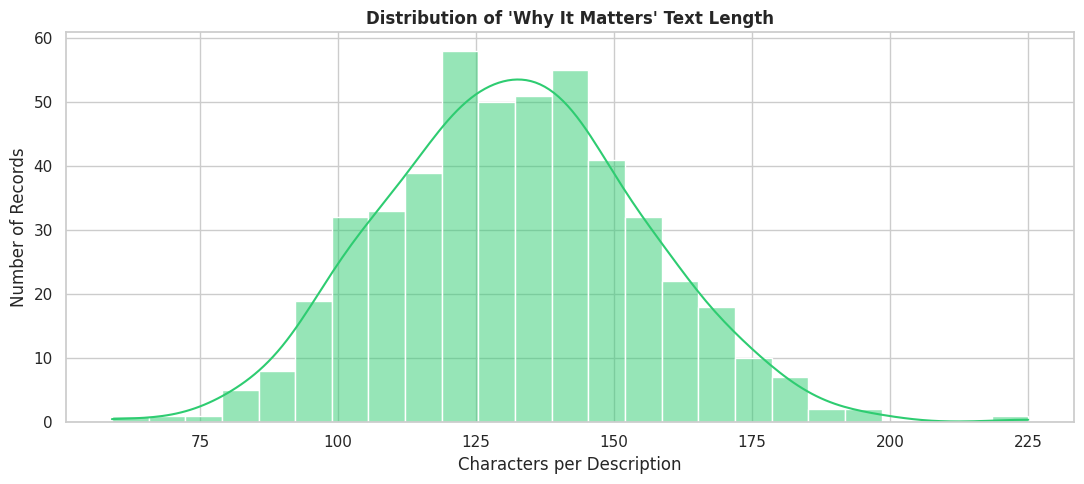

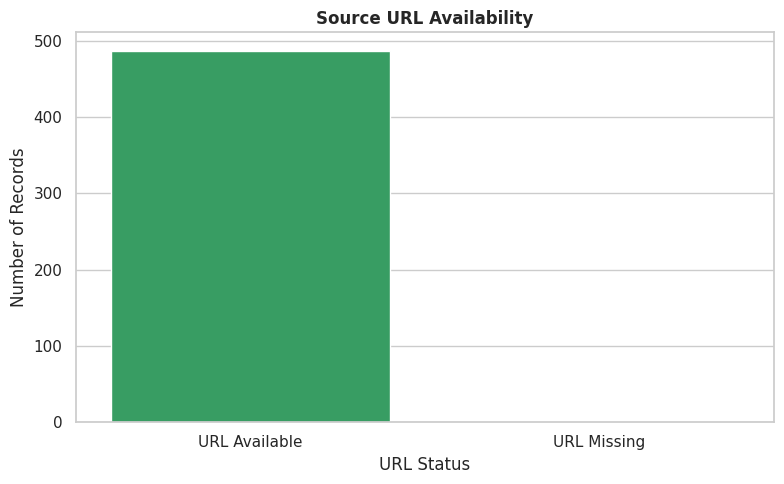


FUNDING & HIRING ANALYTICS SUMMARY
Total records: 488
Unique companies: 339
Total recorded funding: $8,953,900,000.00
Average recorded funding: $165,812,962.96
Average score: 83.85

Funding round counts:
 Funding Round
Venture Round             143
Series A                   84
Series B                   49
Seed                       38
Growth Round               31
                         ... 
Series A / Early Stage      1
Round Extension             1
Angel                       1
Pre-Series B                1
Late-Stage Round            1
Name: count, Length: 80, dtype: int64

Hiring signal counts:
 Hiring Signal
Emerging from stealth with $10M means the company is entering its primary early-stage engineering hiring phase.                                                           1
Massive capital allocation towards AI infrastructure signals aggressive hiring across cloud architecture, backend systems, and high-performance computing engineering.    1
Multi-billion valuation and fu

In [13]:

# -------------------- CONFIGURATION --------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titleweight"] = "bold"

# Expected columns:
# Record ID, Date Found, Company, Funding Amount, Funding Round,
# Event Date, Score, Why It Matters, Hiring Signal, Source Name,
# Source URL, Status

# -------------------- DATA PREPARATION --------------------
df = df.copy()

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert dates
for col in ["Date Found", "Event Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert funding amounts to numeric
# Supports values such as $5M, $500K, $2.5B, and numeric values.
def convert_funding(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    value = str(value).strip().replace(",", "").replace("$", "")
    value = value.replace("USD", "").strip()

    multiplier = 1
    if value.upper().endswith("B"):
        multiplier = 1_000_000_000
        value = value[:-1]
    elif value.upper().endswith("M"):
        multiplier = 1_000_000
        value = value[:-1]
    elif value.upper().endswith("K"):
        multiplier = 1_000
        value = value[:-1]

    try:
        return float(value) * multiplier
    except (ValueError, TypeError):
        return np.nan

if "Funding Amount" in df.columns:
    df["Funding Amount Numeric"] = df["Funding Amount"].apply(
        convert_funding
    )

# Numeric score
if "Score" in df.columns:
    df["Score"] = pd.to_numeric(df["Score"], errors="coerce")

# Text columns
text_cols = [
    "Company", "Funding Round", "Hiring Signal",
    "Source Name", "Status"
]

for col in text_cols:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown").astype(str).str.strip()
        df[col] = df[col].replace("", "Unknown")

# Remove duplicate records when Record ID is available
if "Record ID" in df.columns:
    df = df.drop_duplicates(subset=["Record ID"], keep="first")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nData types:\n", df.dtypes)
print("\nFirst 5 records:\n", df.head())

# -------------------- 1. MISSING VALUES --------------------
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(
        x=missing.index,
        y=missing.values,
        hue=missing.index,
        palette="magma",
        legend=False
    )
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# -------------------- 2. FUNDING AMOUNT DISTRIBUTION --------------------
if "Funding Amount Numeric" in df.columns:
    funding = df["Funding Amount Numeric"].dropna()
    funding = funding[funding >= 0]

    if not funding.empty:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        sns.histplot(
            funding / 1_000_000,
            bins=25,
            kde=True,
            color="#3498DB",
            ax=axes[0]
        )
        axes[0].set_title("Funding Amount Distribution")
        axes[0].set_xlabel("Funding (USD millions)")

        sns.boxplot(
            x=funding / 1_000_000,
            color="#E67E22",
            ax=axes[1]
        )
        axes[1].set_title("Funding Amount Box Plot")
        axes[1].set_xlabel("Funding (USD millions)")

        plt.tight_layout()
        plt.show()

# -------------------- 3. FUNDING BY ROUND --------------------
if {"Funding Round", "Funding Amount Numeric"}.issubset(df.columns):
    round_funding = (
        df.groupby("Funding Round")["Funding Amount Numeric"]
        .sum()
        .sort_values(ascending=False)
    )

    if not round_funding.empty:
        plt.figure(figsize=(12, 6))
        sns.barplot(
            x=round_funding.values / 1_000_000,
            y=round_funding.index,
            hue=round_funding.index,
            palette="viridis",
            legend=False
        )
        plt.title("Total Funding by Funding Round")
        plt.xlabel("Total Funding (USD millions)")
        plt.ylabel("Funding Round")
        plt.tight_layout()
        plt.show()

# -------------------- 4. NUMBER OF RECORDS BY FUNDING ROUND --------------------
if "Funding Round" in df.columns:
    plt.figure(figsize=(12, 6))
    order = df["Funding Round"].value_counts().index

    sns.countplot(
        data=df,
        y="Funding Round",
        order=order,
        hue="Funding Round",
        palette="Set2",
        legend=False
    )
    plt.title("Number of Funding Records by Round")
    plt.xlabel("Number of Records")
    plt.ylabel("Funding Round")
    plt.tight_layout()
    plt.show()

# -------------------- 5. TOP COMPANIES BY FUNDING --------------------
if {"Company", "Funding Amount Numeric"}.issubset(df.columns):
    top_companies = (
        df.groupby("Company")["Funding Amount Numeric"]
        .sum()
        .nlargest(15)
        .sort_values()
    )

    if not top_companies.empty:
        plt.figure(figsize=(12, 7))
        sns.barplot(
            x=top_companies.values / 1_000_000,
            y=top_companies.index,
            hue=top_companies.index,
            palette="rocket",
            legend=False
        )
        plt.title("Top 15 Companies by Total Funding")
        plt.xlabel("Funding (USD millions)")
        plt.ylabel("Company")
        plt.tight_layout()
        plt.show()

# -------------------- 6. TOP COMPANIES BY RECORD COUNT --------------------
if "Company" in df.columns:
    top_count = df["Company"].value_counts().head(15).sort_values()

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=top_count.values,
        y=top_count.index,
        hue=top_count.index,
        palette="crest",
        legend=False
    )
    plt.title("Top 15 Companies by Number of Records")
    plt.xlabel("Record Count")
    plt.ylabel("Company")
    plt.tight_layout()
    plt.show()

# -------------------- 7. SCORE DISTRIBUTION --------------------
if "Score" in df.columns:
    scores = df["Score"].dropna()

    if not scores.empty:
        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        sns.histplot(
            scores,
            bins=20,
            kde=True,
            color="#8E44AD",
            ax=axes[0]
        )
        axes[0].set_title("Score Distribution")

        sns.boxplot(
            x=scores,
            color="#F1C40F",
            ax=axes[1]
        )
        axes[1].set_title("Score Outlier Analysis")

        plt.tight_layout()
        plt.show()

# -------------------- 8. SCORE BY FUNDING ROUND --------------------
if {"Score", "Funding Round"}.issubset(df.columns):
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=df,
        x="Funding Round",
        y="Score",
        hue="Funding Round",
        palette="Set3",
        legend=False
    )
    plt.title("Score Distribution by Funding Round")
    plt.xlabel("Funding Round")
    plt.ylabel("Score")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# -------------------- 9. HIRING SIGNAL DISTRIBUTION --------------------
if "Hiring Signal" in df.columns:
    hiring_counts = df["Hiring Signal"].value_counts().head(15)

    plt.figure(figsize=(12, 6))
    plt.pie(
        hiring_counts.values,
        labels=hiring_counts.index,
        autopct="%1.1f%%",
        startangle=140,
        colors=sns.color_palette("pastel", len(hiring_counts))
    )
    plt.title("Hiring Signal Distribution (Top 15 Categories)")
    plt.tight_layout()
    plt.show()

# -------------------- 10. HIRING SIGNAL COUNTS --------------------
if "Hiring Signal" in df.columns:
    hiring_counts = df["Hiring Signal"].value_counts().head(15).sort_values()

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=hiring_counts.values,
        y=hiring_counts.index,
        hue=hiring_counts.index,
        palette="flare",
        legend=False
    )
    plt.title("Most Common Hiring Signals")
    plt.xlabel("Number of Records")
    plt.ylabel("Hiring Signal")
    plt.tight_layout()
    plt.show()

# -------------------- 11. STATUS DISTRIBUTION --------------------
if "Status" in df.columns:
    status_counts = df["Status"].value_counts()

    plt.figure(figsize=(10, 6))
    plt.pie(
        status_counts.values,
        labels=status_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("Set2", len(status_counts))
    )
    plt.title("Record Status Distribution")
    plt.tight_layout()
    plt.show()

# -------------------- 12. SOURCE NAME DISTRIBUTION --------------------
if "Source Name" in df.columns:
    source_counts = df["Source Name"].value_counts().head(15).sort_values()

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=source_counts.values,
        y=source_counts.index,
        hue=source_counts.index,
        palette="Spectral",
        legend=False
    )
    plt.title("Top 15 Sources by Number of Records")
    plt.xlabel("Number of Records")
    plt.ylabel("Source Name")
    plt.tight_layout()
    plt.show()

# -------------------- 13. RECORDS FOUND OVER TIME --------------------
if "Date Found" in df.columns:
    dates = df.dropna(subset=["Date Found"]).copy()

    if not dates.empty:
        dates["Found Month"] = dates["Date Found"].dt.to_period("M").astype(str)
        monthly = dates.groupby("Found Month").size()

        plt.figure(figsize=(14, 6))
        plt.plot(
            monthly.index,
            monthly.values,
            marker="o",
            linewidth=2.5,
            color="#E74C3C"
        )
        plt.fill_between(
            range(len(monthly)),
            monthly.values,
            alpha=0.18,
            color="#E74C3C"
        )
        plt.title("Records Found Over Time")
        plt.xlabel("Month")
        plt.ylabel("Number of Records")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

# -------------------- 14. EVENTS OVER TIME --------------------
if "Event Date" in df.columns:
    events = df.dropna(subset=["Event Date"]).copy()

    if not events.empty:
        events["Event Month"] = events["Event Date"].dt.to_period("M").astype(str)
        event_monthly = events.groupby("Event Month").size()

        plt.figure(figsize=(14, 6))
        sns.barplot(
            x=event_monthly.index,
            y=event_monthly.values,
            hue=event_monthly.index,
            palette="coolwarm",
            legend=False
        )
        plt.title("Event Timeline by Month")
        plt.xlabel("Event Month")
        plt.ylabel("Number of Events")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

# -------------------- 15. FUNDING TRENDS OVER TIME --------------------
if {"Event Date", "Funding Amount Numeric"}.issubset(df.columns):
    dated_funding = df.dropna(
        subset=["Event Date", "Funding Amount Numeric"]
    ).copy()

    if not dated_funding.empty:
        dated_funding["Event Year"] = dated_funding["Event Date"].dt.year

        yearly_funding = (
            dated_funding.groupby("Event Year")["Funding Amount Numeric"]
            .sum()
            .sort_index()
        )

        plt.figure(figsize=(12, 6))
        plt.plot(
            yearly_funding.index,
            yearly_funding.values / 1_000_000,
            marker="o",
            color="#16A085",
            linewidth=2.5
        )
        plt.title("Total Funding by Event Year")
        plt.xlabel("Year")
        plt.ylabel("Total Funding (USD millions)")
        plt.tight_layout()
        plt.show()

# -------------------- 16. SCORE VS FUNDING --------------------
if {"Score", "Funding Amount Numeric"}.issubset(df.columns):
    scatter_df = df.dropna(
        subset=["Score", "Funding Amount Numeric"]
    )
    scatter_df = scatter_df[scatter_df["Funding Amount Numeric"] >= 0]

    if len(scatter_df) > 0:
        plt.figure(figsize=(12, 7))
        sns.scatterplot(
            data=scatter_df,
            x="Funding Amount Numeric",
            y="Score",
            hue="Funding Round" if "Funding Round" in df.columns else None,
            size="Funding Amount Numeric",
            sizes=(30, 250),
            alpha=0.75,
            palette="husl"
        )
        plt.xscale("symlog", linthresh=1)
        plt.title("Score vs Funding Amount")
        plt.xlabel("Funding Amount (USD, symlog scale)")
        plt.ylabel("Score")
        plt.tight_layout()
        plt.show()

# -------------------- 17. FUNDING ROUND VS HIRING SIGNAL --------------------
if {"Funding Round", "Hiring Signal"}.issubset(df.columns):
    cross_tab = pd.crosstab(df["Funding Round"], df["Hiring Signal"])

    if not cross_tab.empty:
        plt.figure(figsize=(14, 8))
        sns.heatmap(
            cross_tab,
            annot=True,
            fmt="g",
            cmap="YlGnBu",
            linewidths=0.5
        )
        plt.title("Funding Round vs Hiring Signal")
        plt.xlabel("Hiring Signal")
        plt.ylabel("Funding Round")
        plt.tight_layout()
        plt.show()

# -------------------- 18. CORRELATION HEATMAP --------------------
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) >= 2:
    correlation = df[numeric_cols].corr()

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="RdYlBu_r",
        center=0,
        fmt=".2f",
        linewidths=0.5
    )
    plt.title("Numeric Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# -------------------- 19. WHY IT MATTERS TEXT LENGTH --------------------
if "Why It Matters" in df.columns:
    text_length = df["Why It Matters"].dropna().astype(str).str.len()

    if not text_length.empty:
        plt.figure(figsize=(11, 5))
        sns.histplot(
            text_length,
            bins=25,
            kde=True,
            color="#2ECC71"
        )
        plt.title("Distribution of 'Why It Matters' Text Length")
        plt.xlabel("Characters per Description")
        plt.ylabel("Number of Records")
        plt.tight_layout()
        plt.show()

# -------------------- 20. SOURCE URL AVAILABILITY --------------------
if "Source URL" in df.columns:
    urls = df["Source URL"].fillna("").astype(str).str.strip()
    has_url = urls.ne("") & urls.str.lower().ne("nan")
    url_counts = pd.Series({
        "URL Available": int(has_url.sum()),
        "URL Missing": int((~has_url).sum())
    })

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=url_counts.index,
        y=url_counts.values,
        hue=url_counts.index,
        palette=["#27AE60", "#C0392B"],
        legend=False
    )
    plt.title("Source URL Availability")
    plt.xlabel("URL Status")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

# -------------------- 21. DASHBOARD SUMMARY --------------------
print("\n" + "=" * 60)
print("FUNDING & HIRING ANALYTICS SUMMARY")
print("=" * 60)

print(f"Total records: {len(df)}")

if "Company" in df.columns:
    print(f"Unique companies: {df['Company'].nunique()}")

if "Funding Amount Numeric" in df.columns:
    print(
        "Total recorded funding: $"
        f"{df['Funding Amount Numeric'].sum(skipna=True):,.2f}"
    )
    print(
        "Average recorded funding: $"
        f"{df['Funding Amount Numeric'].mean():,.2f}"
    )

if "Score" in df.columns:
    print(f"Average score: {df['Score'].mean():.2f}")

if "Funding Round" in df.columns:
    print("\nFunding round counts:\n", df["Funding Round"].value_counts())

if "Hiring Signal" in df.columns:
    print("\nHiring signal counts:\n", df["Hiring Signal"].value_counts().head(10))

if "Status" in df.columns:
    print("\nStatus counts:\n", df["Status"].value_counts())

print("\nAll available visualizations completed successfully.")


## Feature engineering

STARTUP FUNDING AND HIRING: MACHINE LEARNING
Original dataset shape: (488, 13)
Columns: ['Record ID', 'Date Found', 'Company', 'Funding Amount', 'Funding Round', 'Event Date', 'Score', 'Why It Matters', 'Hiring Signal', 'Source Name', 'Source URL', 'Status', 'Funding Amount Numeric']

Target distribution:
Status
OLD    478
NEW     10
Name: count, dtype: int64

Target percentages:
Status
OLD    97.95
NEW     2.05
Name: proportion, dtype: float64

Encoded target classes:
NEW -> 0
OLD -> 1

Features used: ['Company', 'Funding Amount', 'Funding Round', 'Score', 'Hiring Signal', 'Source Name', 'Funding Amount Numeric', 'Event Date Month', 'Event Date Day', 'Event Date DayOfWeek']
Number of features before encoding: 10

Numeric features: ['Funding Amount', 'Score', 'Funding Amount Numeric', 'Event Date Month', 'Event Date Day', 'Event Date DayOfWeek']
Categorical features: ['Company', 'Funding Round', 'Hiring Signal', 'Source Name']

Training feature shape: (366, 10)
Testing feature shape: (

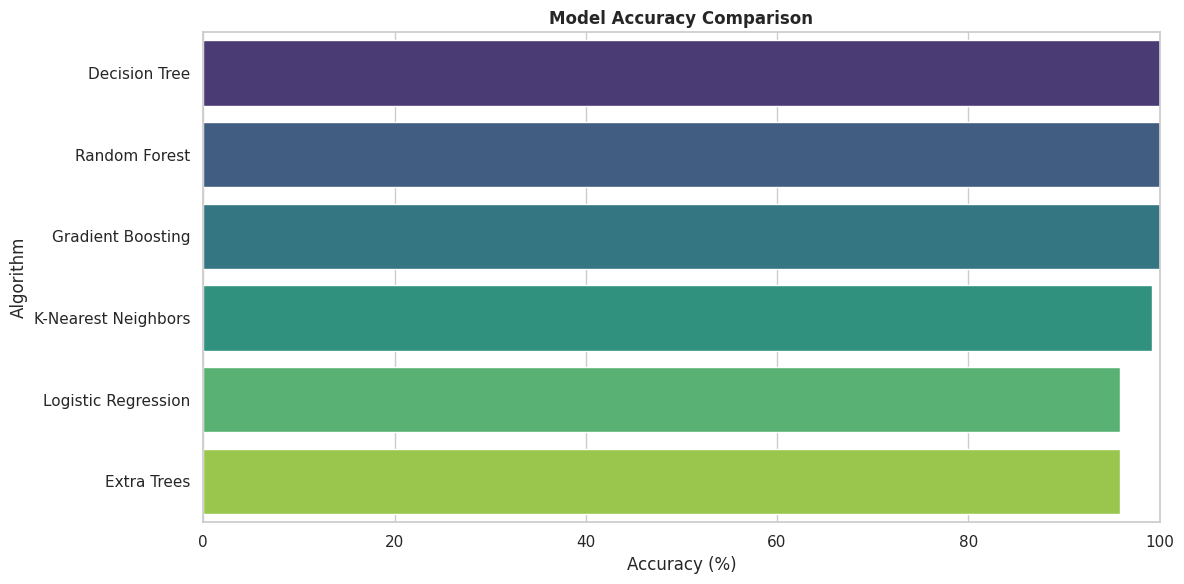

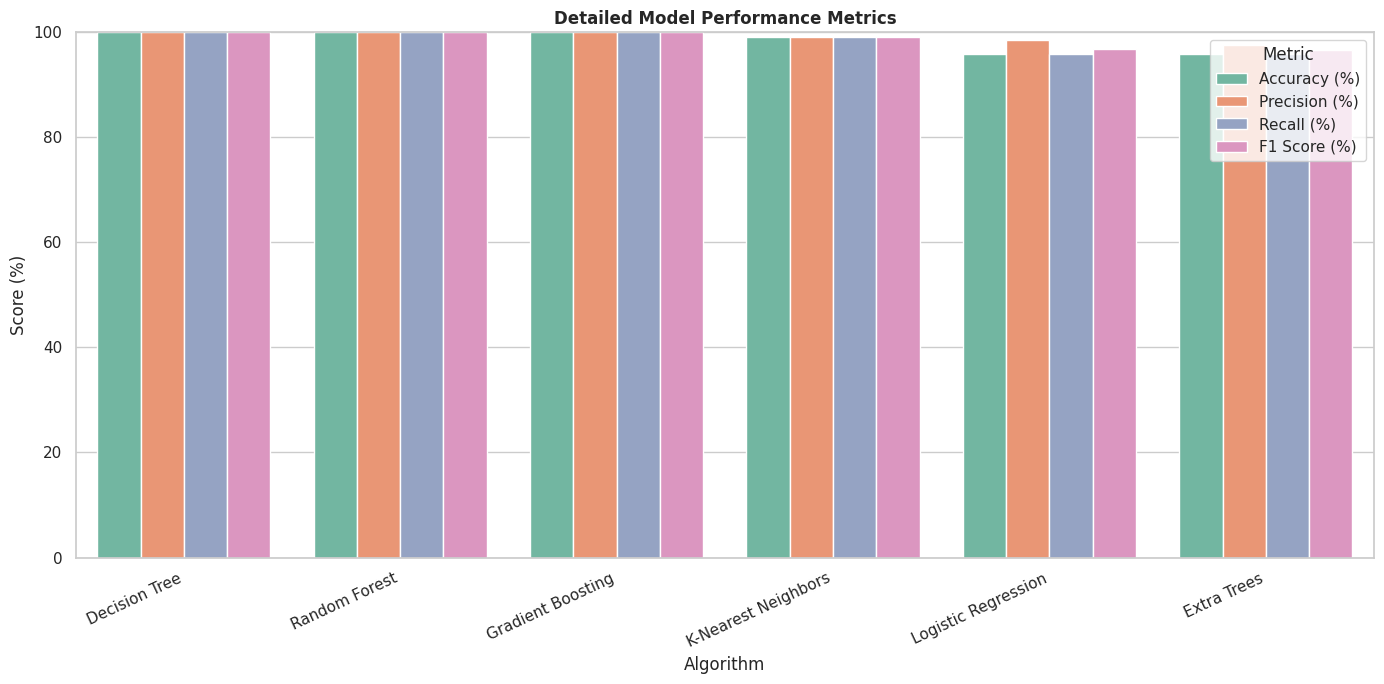

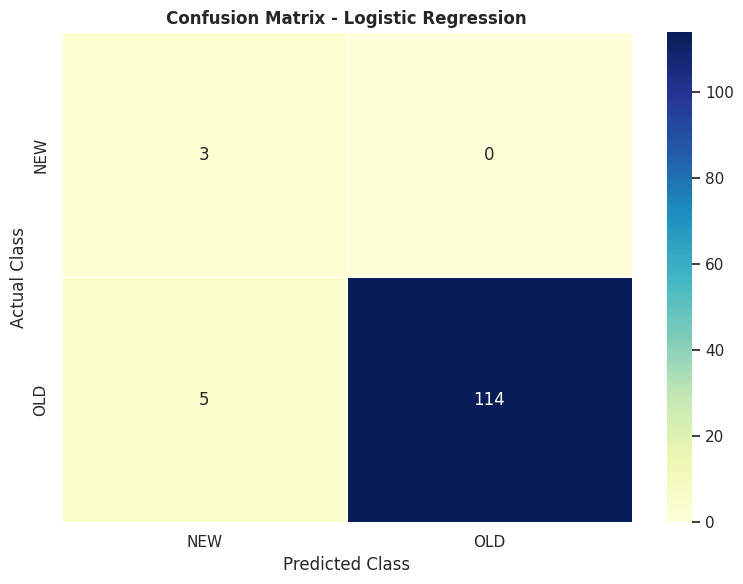

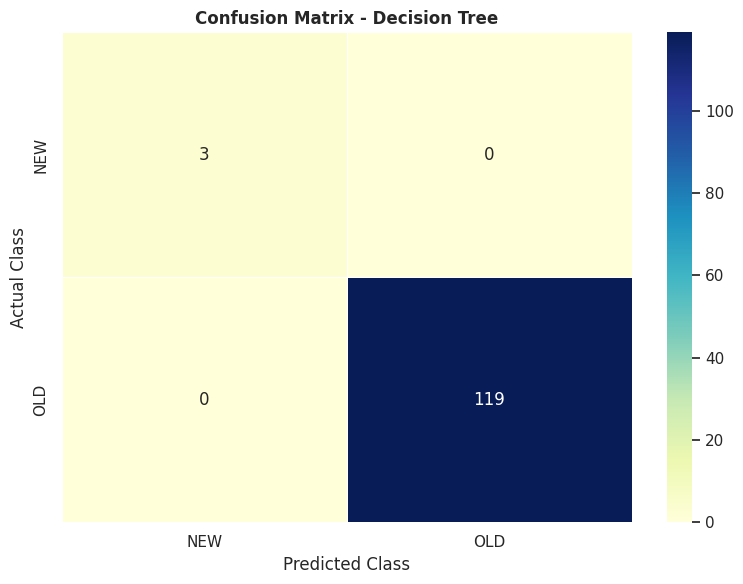

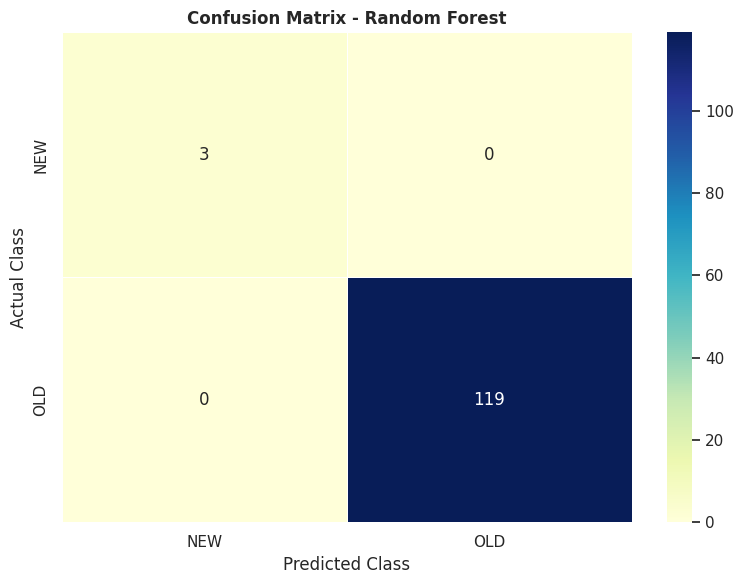

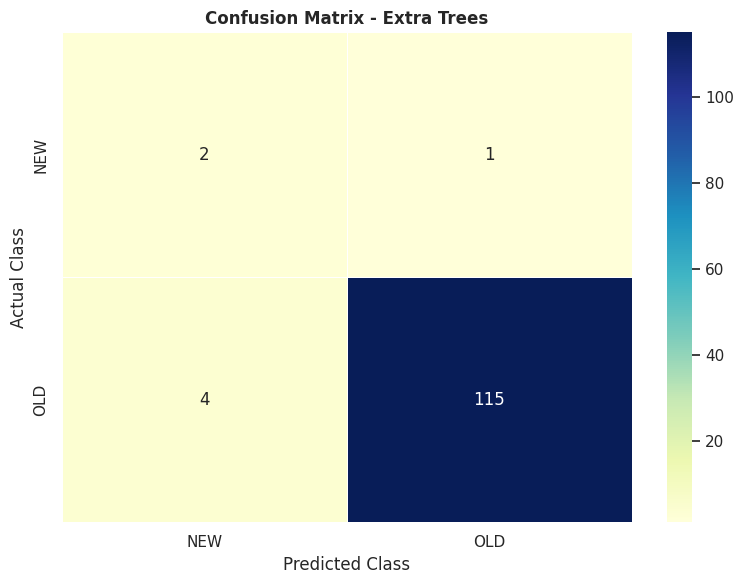

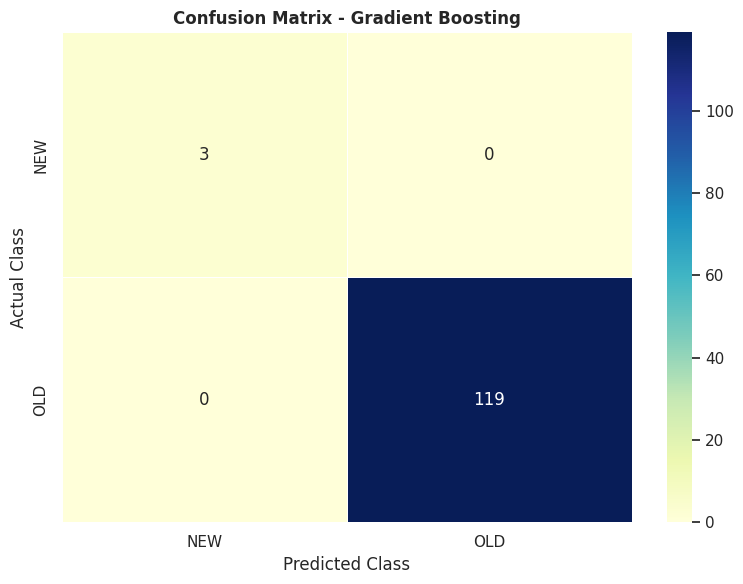

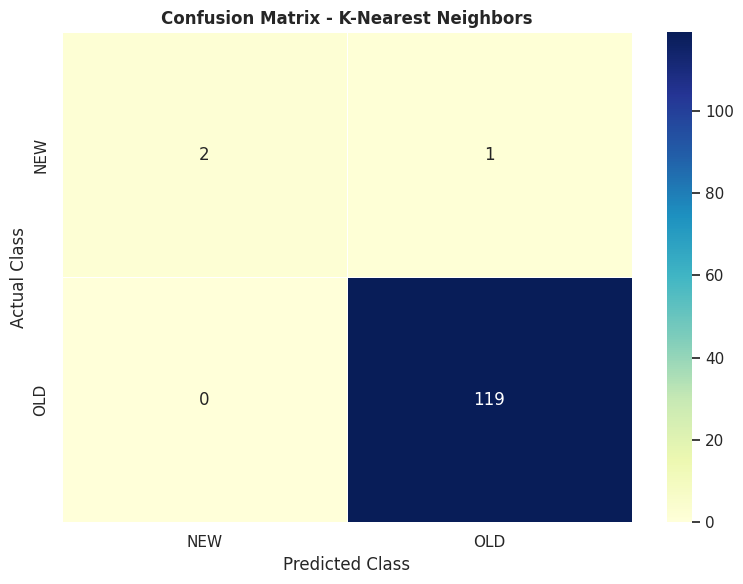

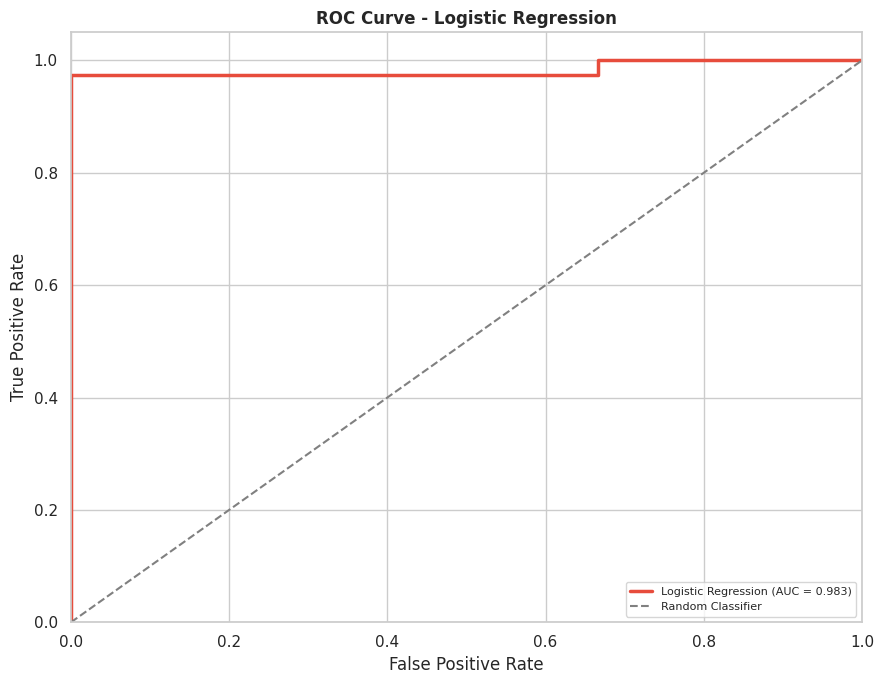

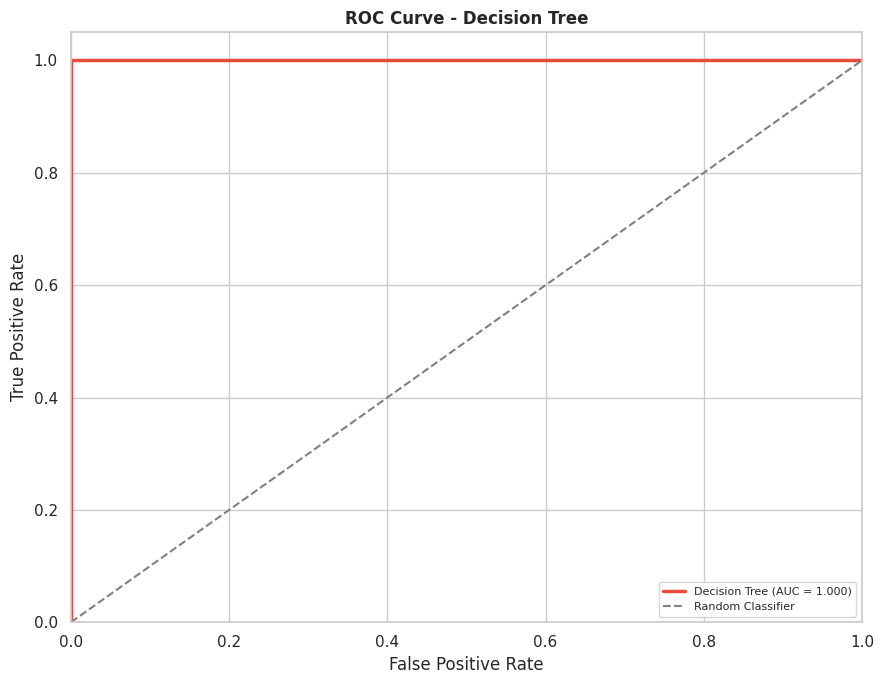

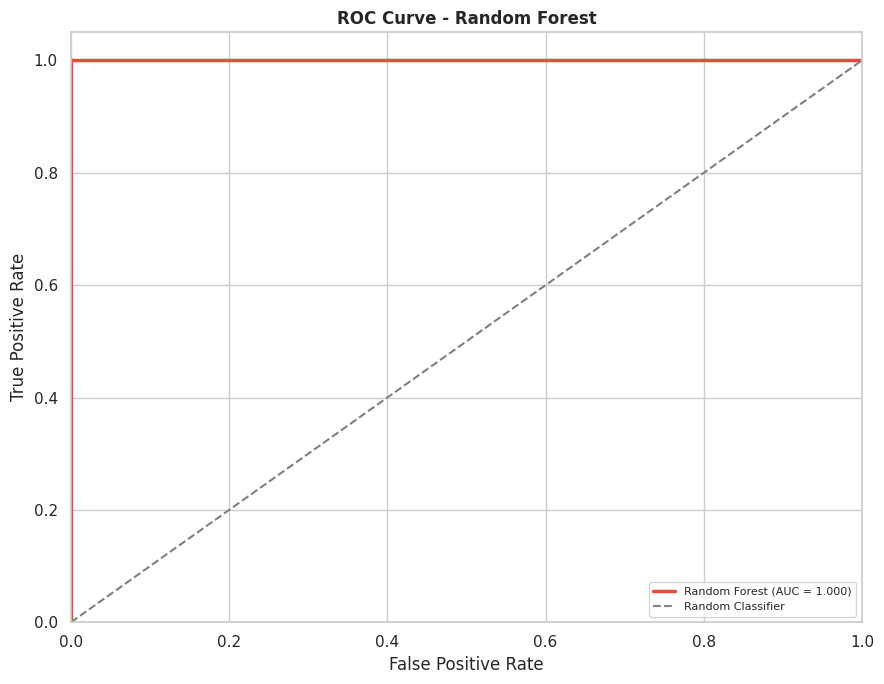

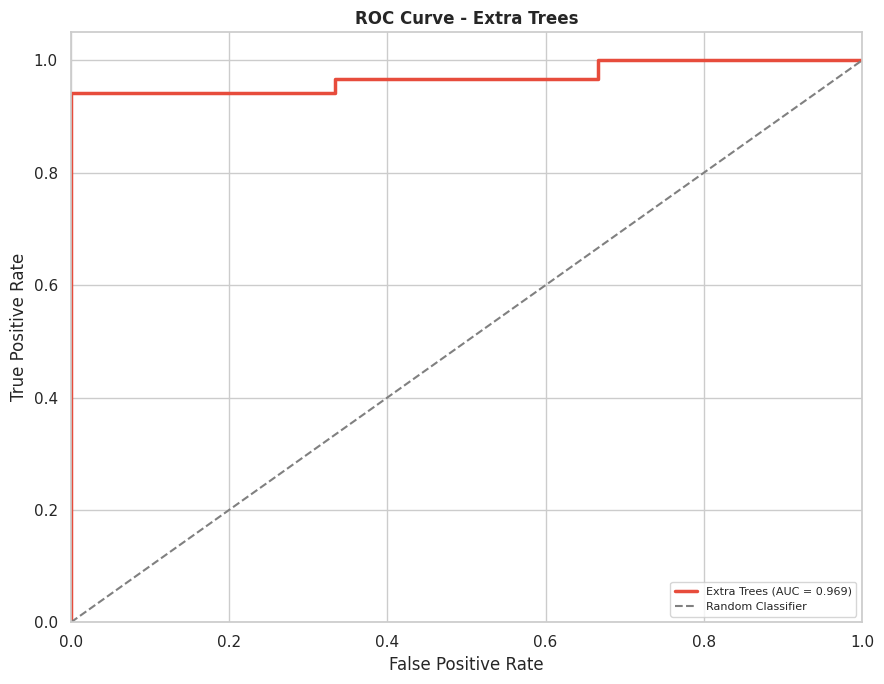

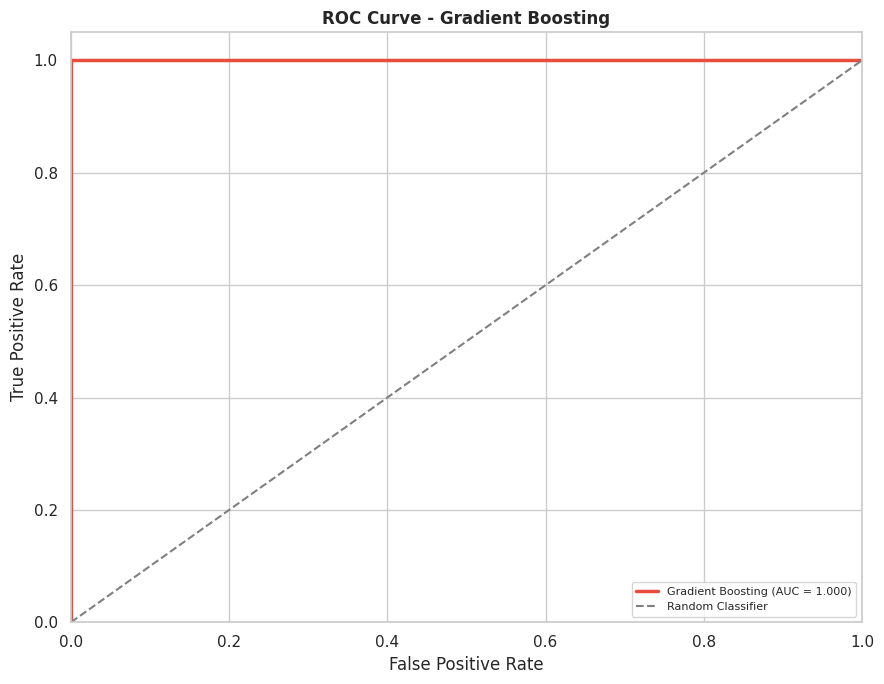

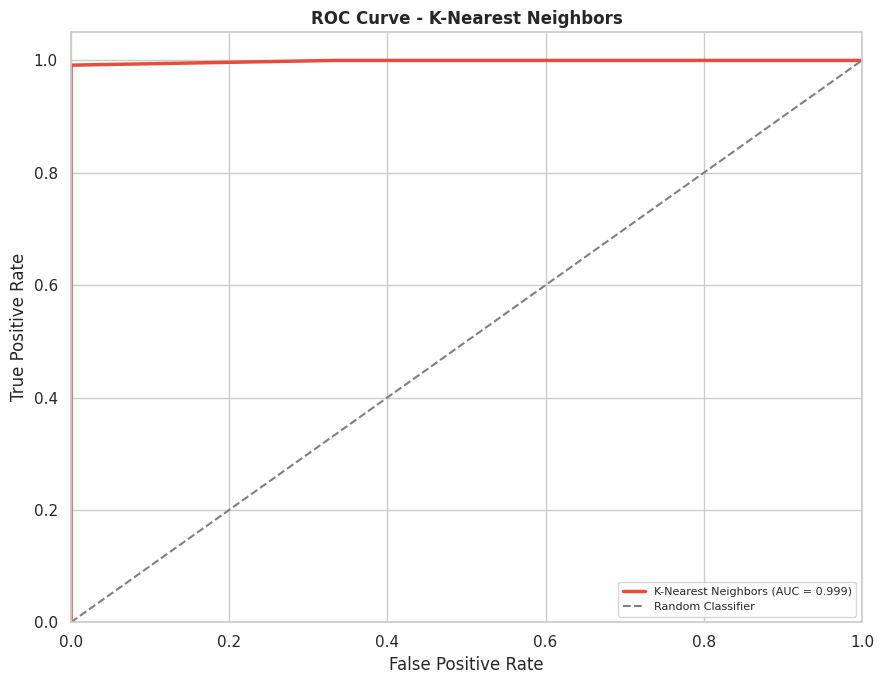

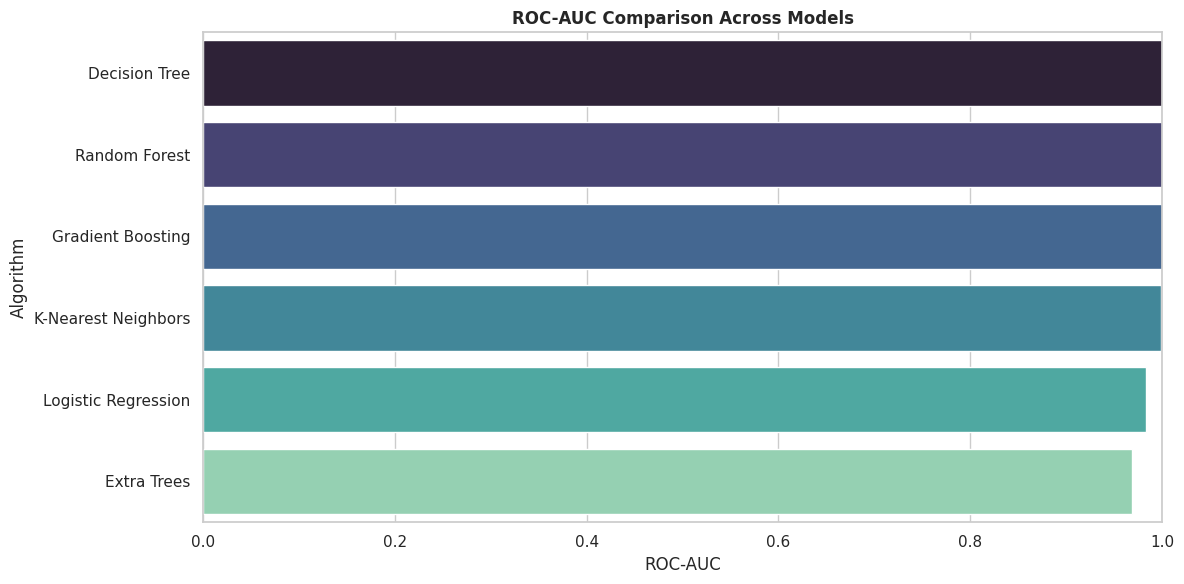


BEST MODEL SUMMARY
Selected by weighted F1 Score: Decision Tree
Model            Decision Tree
Accuracy (%)             100.0
Precision (%)            100.0
Recall (%)               100.0
F1 Score (%)             100.0
ROC-AUC                    1.0

Important notes:
1. The target is the existing Status column.
2. LabelEncoder encodes the target classes only.
3. OneHotEncoder encodes categorical input features.
4. Imputation and scaling are fitted on training data only.
5. Metrics are calculated on the held-out test set.
6. ROC curves use predicted probabilities.
7. Results do not guarantee future performance.

Saved results to startup_ml_model_comparison.csv


In [14]:


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder, OneHotEncoder, StandardScaler, label_binarize
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

# -------------------- 1. CONFIGURATION --------------------

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
TARGET = "Status"

# Work on a copy; original df remains unchanged.
data = df.copy()
data.columns = data.columns.str.strip()

print("=" * 70)
print("STARTUP FUNDING AND HIRING: MACHINE LEARNING")
print("=" * 70)

print("Original dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

# -------------------- 2. VALIDATE TARGET --------------------

if TARGET not in data.columns:
    raise ValueError(
        f"Target '{TARGET}' was not found. "
        "Choose an existing meaningful target column."
    )

# Missing target values cannot be used for supervised learning.
data = data.dropna(subset=[TARGET]).copy()

# Normalize target labels without inventing new labels.
data[TARGET] = data[TARGET].astype(str).str.strip()
data = data[data[TARGET].ne("") & data[TARGET].str.lower().ne("nan")]

# Remove duplicate Record IDs if available.
if "Record ID" in data.columns:
    data = data.drop_duplicates(subset=["Record ID"], keep="first")

print("\nTarget distribution:")
print(data[TARGET].value_counts())

print("\nTarget percentages:")
print((data[TARGET].value_counts(normalize=True) * 100).round(2))

# Remove classes that have fewer than two examples.
# Stratified splitting requires at least two examples per class.
class_counts = data[TARGET].value_counts()
rare_classes = class_counts[class_counts < 2].index.tolist()

if rare_classes:
    print("\nWARNING: Removing rows with classes too rare to split:")
    print(rare_classes)
    data = data[~data[TARGET].isin(rare_classes)].copy()

if data[TARGET].nunique() < 2:
    raise ValueError(
        "Classification requires at least two target classes "
        "with sufficient examples. Check the Status column."
    )

if data[TARGET].value_counts().min() < 2:
    raise ValueError("Not enough examples per class for train-test splitting.")

# -------------------- 3. FEATURE ENGINEERING --------------------

# Convert funding amounts such as $5M, $200K, or $1.5B.
def parse_funding(value):
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    value = str(value).strip().replace(",", "").replace("$", "")
    value = value.replace("USD", "").strip()

    multiplier = 1.0

    if value.upper().endswith("B"):
        multiplier = 1_000_000_000
        value = value[:-1]
    elif value.upper().endswith("M"):
        multiplier = 1_000_000
        value = value[:-1]
    elif value.upper().endswith("K"):
        multiplier = 1_000
        value = value[:-1]

    try:
        return float(value) * multiplier
    except (ValueError, TypeError):
        return np.nan


if "Funding Amount" in data.columns:
    data["Funding Amount"] = data["Funding Amount"].apply(parse_funding)

# Convert dates to useful numeric features.
# Original date columns will not be fed directly into the models.
for col in ["Date Found", "Event Date"]:
    if col in data.columns:
        dates = pd.to_datetime(data[col], errors="coerce")
        data[col + " Year"] = dates.dt.year
        data[col + " Month"] = dates.dt.month
        data[col + " Day"] = dates.dt.day
        data[col + " DayOfWeek"] = dates.dt.dayofweek

# Record ID, URLs, and free-text explanations are excluded.
# This helps avoid memorization, excessive dimensions, and leakage.
drop_cols = [
    TARGET,
    "Record ID",
    "Date Found",
    "Event Date",
    "Source URL",
    "Why It Matters"
]

X = data.drop(
    columns=[c for c in drop_cols if c in data.columns]
).copy()

y_original = data[TARGET].copy()

# Remove entirely empty features and constant features.
X = X.dropna(axis=1, how="all")
constant_cols = [
    c for c in X.columns if X[c].nunique(dropna=True) <= 1
]
X = X.drop(columns=constant_cols)

if X.shape[1] == 0:
    raise ValueError("No usable features remain after preprocessing.")

# -------------------- 4. LABEL ENCODING --------------------

# LabelEncoder is appropriate for the classification target.
# Feature categories will use OneHotEncoder to avoid false ordering.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original.astype(str))

class_names = label_encoder.classes_
n_classes = len(class_names)

print("\nEncoded target classes:")
for encoded_value, class_name in enumerate(class_names):
    print(f"{class_name} -> {encoded_value}")

print("\nFeatures used:", X.columns.tolist())
print("Number of features before encoding:", X.shape[1])

# -------------------- 5. IDENTIFY FEATURE TYPES --------------------

# Attempt to convert numeric-looking object columns to numeric.
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")

        # Convert only when almost all non-missing values are numeric.
        original_nonmissing = X[col].notna().sum()
        if original_nonmissing > 0:
            numeric_ratio = converted.notna().sum() / original_nonmissing
            if numeric_ratio >= 0.90:
                X[col] = converted

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

# -------------------- 6. TRAIN-TEST SPLITTING --------------------

# Reserve enough rows for the test set to represent every class.
test_fraction = max(0.25, (n_classes + 1) / len(y))

if test_fraction >= 0.50:
    test_fraction = 0.50

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_fraction,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_train)
).value_counts())

print("\nTesting target distribution:")
print(pd.Series(
    label_encoder.inverse_transform(y_test)
).value_counts())

# -------------------- 7. PREPROCESSING PIPELINE --------------------

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# -------------------- 8. DEFINE ML ALGORITHMS --------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=min(5, len(X_train))
    )
}

# -------------------- 9. TRAIN AND EVALUATE MODELS --------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}
confusion_matrices = {}

for model_name, classifier in models.items():

    print("\n" + "=" * 65)
    print("Training:", model_name)
    print("=" * 65)

    # Each model gets its own fitted preprocessing pipeline.
    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    try:
        model_pipeline.fit(X_train, y_train)

        y_pred = model_pipeline.predict(X_test)
        y_prob = model_pipeline.predict_proba(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )

        # ROC-AUC: binary or multiclass.
        try:
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, y_prob[:, 1])
            else:
                roc_auc = roc_auc_score(
                    y_test,
                    y_prob,
                    labels=np.arange(n_classes),
                    multi_class="ovr",
                    average="macro"
                )
        except ValueError:
            roc_auc = np.nan

        results.append({
            "Model": model_name,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1 Score (%)": f1 * 100,
            "ROC-AUC": roc_auc
        })

        trained_models[model_name] = model_pipeline
        predictions[model_name] = y_pred
        probabilities[model_name] = y_prob
        confusion_matrices[model_name] = confusion_matrix(
            y_test,
            y_pred,
            labels=np.arange(n_classes)
        )

        print(f"Accuracy:  {accuracy * 100:.2f}%")
        print(f"Precision: {precision * 100:.2f}%")
        print(f"Recall:    {recall * 100:.2f}%")
        print(f"F1 Score:  {f1 * 100:.2f}%")
        print(f"ROC-AUC:   {roc_auc:.4f}" if not np.isnan(roc_auc)
              else "ROC-AUC: unavailable")

        print("\nClassification report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(n_classes),
            target_names=class_names,
            zero_division=0
        ))

    except Exception as error:
        print(f"Model failed: {error}")

if not results:
    raise RuntimeError(
        "All models failed. Check dataset size, feature values, "
        "and target distribution."
    )

# -------------------- 10. MODEL COMPARISON --------------------

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score (%)", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

# -------------------- 11. ACCURACY COMPARISON --------------------

plt.figure(figsize=(12, 6))
sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)
plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Algorithm")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# -------------------- 12. PRECISION, RECALL AND F1 --------------------

metric_columns = [
    "Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)"
]

metric_plot = results_df.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score (%)"
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=metric_plot,
    x="Model",
    y="Score (%)",
    hue="Metric",
    palette="Set2"
)
plt.title("Detailed Model Performance Metrics")
plt.ylabel("Score (%)")
plt.xlabel("Algorithm")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# -------------------- 13. CONFUSION MATRICES --------------------

for model_name, cm in confusion_matrices.items():
    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

# -------------------- 14. ROC CURVES --------------------

# ROC curves require probabilities, not predicted class labels.
# Binary: one curve per model.
# Multiclass: one-vs-rest curves for each class and each model.

for model_name, y_prob in probabilities.items():

    plt.figure(figsize=(9, 7))

    if n_classes == 2:
        fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, 1])
        model_auc = auc(fpr, tpr)

        plt.plot(
            fpr, tpr,
            linewidth=2.5,
            color="#E74C3C",
            label=f"{model_name} (AUC = {model_auc:.3f})"
        )

    else:
        y_test_binary = label_binarize(
            y_test, classes=np.arange(n_classes)
        )

        colors = sns.color_palette("husl", n_classes)

        for class_index, class_name in enumerate(class_names):
            # A class must have positive and negative test examples.
            if len(np.unique(y_test_binary[:, class_index])) < 2:
                continue

            fpr, tpr, thresholds = roc_curve(
                y_test_binary[:, class_index],
                y_prob[:, class_index]
            )

            class_auc = auc(fpr, tpr)

            plt.plot(
                fpr, tpr,
                linewidth=2,
                color=colors[class_index],
                label=f"{class_name} (AUC = {class_auc:.3f})"
            )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label="Random Classifier"
    )

    plt.title(f"ROC Curve - {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.xlim(0, 1)
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

# -------------------- 15. ROC-AUC COMPARISON --------------------

auc_df = results_df.dropna(subset=["ROC-AUC"]).sort_values(
    "ROC-AUC", ascending=False
)

if not auc_df.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=auc_df,
        x="ROC-AUC",
        y="Model",
        hue="Model",
        palette="mako",
        legend=False
    )

    plt.title("ROC-AUC Comparison Across Models")
    plt.xlabel("ROC-AUC")
    plt.ylabel("Algorithm")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()

# -------------------- 16. BEST MODEL SUMMARY --------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 70)
print("BEST MODEL SUMMARY")
print("=" * 70)
print("Selected by weighted F1 Score:", best_model_name)
print(results_df.iloc[0].to_string())

print("\nImportant notes:")
print("1. The target is the existing Status column.")
print("2. LabelEncoder encodes the target classes only.")
print("3. OneHotEncoder encodes categorical input features.")
print("4. Imputation and scaling are fitted on training data only.")
print("5. Metrics are calculated on the held-out test set.")
print("6. ROC curves use predicted probabilities.")
print("7. Results do not guarantee future performance.")

# Optional: save model comparison results
results_df.to_csv("startup_ml_model_comparison.csv", index=False)
print("\nSaved results to startup_ml_model_comparison.csv")

## Thank you pls upvote!!!!!!!!!!!